# XRL-MODAL: Adaptive Intermodal Cold-Chain Transportation


## Multimodal XRL Implementation and Model Comparison


### Project Configuration


In [1]:
import json
import math
import os
import random
import re
import time
import warnings
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from stable_baselines3 import DQN, PPO, SAC, TD3
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor

#### Main Project Directories


In [2]:
PROJECT_ROOT = Path("./")

DATA_ROOT = PROJECT_ROOT / "data"
RESULTS_ROOT = PROJECT_ROOT / "results"
PLOTS_ROOT = RESULTS_ROOT / "plots"
METRICS_ROOT = RESULTS_ROOT / "metrics"
MODELS_ROOT = RESULTS_ROOT / "models"
EXPLANATIONS_ROOT = RESULTS_ROOT / "explanations"
LOGS_ROOT = RESULTS_ROOT / "logs"
PREPROCESSING_ROOT = RESULTS_ROOT / "preprocessing"

In [3]:
for directory in [
    RESULTS_ROOT,
    PLOTS_ROOT,
    METRICS_ROOT,
    MODELS_ROOT,
    EXPLANATIONS_ROOT,
    LOGS_ROOT,
    PREPROCESSING_ROOT,
]:
    directory.mkdir(parents=True, exist_ok=True)


for algorithm_name in ["PPO", "SAC", "TD3", "DQN"]:
    (PLOTS_ROOT / algorithm_name).mkdir(parents=True, exist_ok=True)
    (MODELS_ROOT / algorithm_name).mkdir(parents=True, exist_ok=True)
    (LOGS_ROOT / algorithm_name).mkdir(parents=True, exist_ok=True)


(PLOTS_ROOT / "comparison").mkdir(parents=True, exist_ok=True)

#### Reproducibility


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#### Training Configuration


In [5]:
CONFIG = {
    "seed": SEED,
    # Increase these for the final research experiment.
    "ppo_timesteps": 50_000,
    "sac_timesteps": 50_000,
    "td3_timesteps": 50_000,
    "dqn_timesteps": 50_000,
    "evaluation_episodes": 30,
    "episode_length": 30,
    "learning_rate": 3e-4,
    "batch_size": 256,
    "gamma": 0.99,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    # Modal switching formulation from the project concept.
    "modes": [
        "Road",
        "Rail",
        "Sea",
        "Air",
        "Inland Waterway",
    ],
    # Reward coefficients.
    # These are configurable research parameters. All underlying quantities are normalized before use.
    "reward_weights": {
        "freshness": 1.00,
        "cost": 0.75,
        "time": 0.75,
        "emission": 0.75,
        "risk": 0.75,
        "switch": 0.25,
    },
}


with open(RESULTS_ROOT / "project_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=4)


MODE_TO_ID = {mode: i for i, mode in enumerate(CONFIG["modes"])}

ID_TO_MODE = {i: mode for mode, i in MODE_TO_ID.items()}


print("Data root:", DATA_ROOT)
print("Device:", CONFIG["device"])
print("Modes:", CONFIG["modes"])

Data root: data
Device: cuda
Modes: ['Road', 'Rail', 'Sea', 'Air', 'Inland Waterway']


### Exact Project Dataset Manifest


In [6]:
DATASETS = {
    "accidents": [
        "city_wise_accedents_classified_according_to_type_of_traffic_control_at_junctions_during_2024.csv",
        "city_wise_accidents_classified_according_to_road_features_during_2024.csv",
        "city_wise_accidents_classified_according_to_type_of_impacting_vehicles_objects_during_2024.csv",
        "city_wise_accidents_classified_according_to_type_of_junctions_during_2024.csv",
        "city_wise_accidents_classified_according_to_type_of_traffic_rule_violations_during_2024.csv",
        "state_wise_list_of_top_ten_black_spots_from_2016_to_2018.csv",
        "year_wise_details_of_road_accidents_persons_killed_and_injured_from_1970_to_2024.csv",
    ],
    "cold_chain": [
        "approved-cold-chain-projects.csv",
        "integrated-cold-chain-availability-component-details.csv",
        "integrated-cold-chain-availability-cost-report.csv",
    ],
    "cold_storage": [
        "state_ut_wise_details_of_distribution_of_cold_storages_2025.csv",
    ],
    "emissions": {
        "co2_emissions": [
            "carbon_dioxide_emissions_from_various_transport_modes_in_india.csv",
        ],
    },
    "freight": [
        "freight_and_passenger_movement_by_road_transport_and_railways_during_1950-51_to_2006-07.csv",
        "freight_and_passenger_movement_by_road_transport_and_railways_during_1999-2000_to_2011-12.csv",
    ],
    "fruits": [
        "all_india_level_area_and_production_of_fruits.csv",
        "area_and_production_of_fruits.csv",
        "state_wise_area_and_production_of_fruits.csv",
    ],
    "icd": [
        "state_wise_total_number_of_dry_ports_inland_container_depot.csv",
    ],
    "iot": [
        "multimodal_iot_supply_chain_dataset.csv",
        "smart_logistics_dataset.csv",
    ],
    "rainfall": [
        "rainfall_area-wt_India_1901-2015.csv",
        "rainfall_area-wt_sd_1901-2015.csv",
        "sub_division_imd_2017.csv",
    ],
    "roads": [
        "state_and_ut-wise_road_density_per_1000_sq._km_for_different_catogories_of_roads.csv",
        "state_and_ut-wise_road_density_per_1000_sq._km_of_roads_in_rural_and_urban_area_as_on_31_march_2019.csv",
        "state_and_ut-wise_road_length_per_1000_population_for_different_categories_of_roads.csv",
        "state_and_ut-wise_total_and_surfaced_length_of_rural_roads_as_on_31_march_2019.csv",
        "state_and_ut-wise_total_and_surfaced_length_of_urban_roads_as_on_31_march_2019.csv",
    ],
    "temperature": [
        "temp_annual_mean_1901-2021.csv",
        "temp_annual_min_max_1901-2021.csv",
    ],
    "vegetables": [
        "area_and_production_of_vegetables.csv",
        "Table_9.6-All_india_Horticulture.csv",
        "Table_9.6-State_wise_Horticulture.csv",
    ],
    "wpi": [
        "wholesale_price_index.csv",
    ],
    "ports": {
        "dwell_time": [
            "dgqi_2020.csv",
            "dgqi_2021.csv",
            "dgqi_2022.csv",
        ],
        "port_traffic": [
            "chennai.csv",
            "cochin.csv",
            "deendayal.csv",
            "jawahar_lal_nehru.csv",
            "kamarajar.csv",
            "kandla.csv",
            "kolkata_haldia.csv",
            "mormugao.csv",
            "mumbai.csv",
            "new_mangalore.csv",
            "paradip.csv",
            "vishakhapatnam.csv",
            "vo_chidambaranar.csv",
        ],
    },
}

### Dataset Discovery


In [7]:
def discover_dataset_files(root: Path):
    csv_files = sorted(root.rglob("*.csv"))
    nc_files = sorted(root.rglob("*.nc"))
    pbf_files = sorted(root.rglob("*.osm.pbf"))

    return csv_files, nc_files, pbf_files


csv_files, nc_files, pbf_files = discover_dataset_files(DATA_ROOT)

print(f"CSV files discovered: {len(csv_files)}")
print(f"NetCDF files: {len(nc_files)}")
print(f"OSM PBF files: {len(pbf_files)}")

CSV files discovered: 50
NetCDF files: 30
OSM PBF files: 1


### Dataset Validation


In [8]:
def read_csv_robust(path: Path):
    encodings = ["utf-8-sig", "utf-8", "cp1252", "latin1"]

    last_error = None

    for encoding in encodings:
        try:
            return pd.read_csv(path, encoding=encoding)
        except Exception as exc:
            last_error = exc

    raise RuntimeError(f"Unable to read {path}. Last error: {last_error}")


# Recursive manifest validation
def validate_manifest(root: Path, manifest: dict):
    missing = []

    def validate_entries(current_path, entries):
        for name, value in entries.items():
            if isinstance(value, dict):
                validate_entries(current_path / name, value)

            elif isinstance(value, list):
                for filename in value:
                    file_path = current_path / filename

                    if not file_path.is_file():
                        missing.append(str(file_path))

    validate_entries(root, manifest)

    return missing


missing_files = validate_manifest(DATA_ROOT, DATASETS)

if missing_files:
    print("Missing manifest files:")
    for path in missing_files:
        print("  ", path)
else:
    print("All manifest CSV files are present.")


# Recursive CSV loading
def load_manifest_entries(current_path: Path, entries: dict):

    loaded = {}

    for name, value in entries.items():
        if isinstance(value, dict):
            # Nested directory
            loaded[name] = load_manifest_entries(current_path / name, value)

        elif isinstance(value, list):
            # CSV files inside the current directory
            loaded[name] = {}

            for filename in value:
                file_path = current_path / filename

                if not file_path.is_file():
                    continue

                df = read_csv_robust(file_path)

                loaded[name][filename] = df

                print(f"{str(file_path.relative_to(DATA_ROOT)):75s} | shape={df.shape}")

    return loaded


# Load all manifest datasets

DATA = load_manifest_entries(DATA_ROOT, DATASETS)

print("\nDataset loading completed.")

Missing manifest files:
   data/city_wise_accedents_classified_according_to_type_of_traffic_control_at_junctions_during_2024.csv
   data/city_wise_accidents_classified_according_to_road_features_during_2024.csv
   data/city_wise_accidents_classified_according_to_type_of_impacting_vehicles_objects_during_2024.csv
   data/city_wise_accidents_classified_according_to_type_of_junctions_during_2024.csv
   data/city_wise_accidents_classified_according_to_type_of_traffic_rule_violations_during_2024.csv
   data/state_wise_list_of_top_ten_black_spots_from_2016_to_2018.csv
   data/year_wise_details_of_road_accidents_persons_killed_and_injured_from_1970_to_2024.csv
   data/approved-cold-chain-projects.csv
   data/integrated-cold-chain-availability-component-details.csv
   data/integrated-cold-chain-availability-cost-report.csv
   data/state_ut_wise_details_of_distribution_of_cold_storages_2025.csv
   data/emissions/carbon_dioxide_emissions_from_various_transport_modes_in_india.csv
   data/freight_

### Load All CSV Datasets


In [9]:
def read_csv_robust(path: Path):
    encodings = [
        "utf-8-sig",
        "utf-8",
        "cp1252",
        "latin1",
    ]

    last_error = None

    for encoding in encodings:
        try:
            return pd.read_csv(path, encoding=encoding)
        except Exception as exc:
            last_error = exc

    raise RuntimeError(f"Unable to read {path}. Last error: {last_error}")


def load_dataset_folder(folder_path: Path, manifest):
    """
    Recursively load CSV files using the DATASETS manifest.

    A list represents CSV filenames in the current folder.
    A dictionary represents nested subfolders.
    """

    loaded = {}

    # Nested directory structure
    if isinstance(manifest, dict):
        for subfolder, sub_manifest in manifest.items():
            subfolder_path = folder_path / subfolder

            loaded[subfolder] = load_dataset_folder(subfolder_path, sub_manifest)

    # CSV filenames in the current directory
    elif isinstance(manifest, list):
        for filename in manifest:
            path = folder_path / filename

            if not path.is_file():
                print(f"WARNING: File not found: {path}")
                continue

            df = read_csv_robust(path)

            loaded[filename] = df

            print(f"{str(path.relative_to(DATA_ROOT)):75s} | shape={df.shape}")

    return loaded


# Load every dataset
DATA = {}

for folder, manifest in DATASETS.items():
    folder_path = DATA_ROOT / folder

    DATA[folder] = load_dataset_folder(folder_path, manifest)

print("\nDataset loading completed.")

accidents/city_wise_accedents_classified_according_to_type_of_traffic_control_at_junctions_during_2024.csv | shape=(51, 29)
accidents/city_wise_accidents_classified_according_to_road_features_during_2024.csv | shape=(51, 44)
accidents/city_wise_accidents_classified_according_to_type_of_impacting_vehicles_objects_during_2024.csv | shape=(51, 38)
accidents/city_wise_accidents_classified_according_to_type_of_junctions_during_2024.csv | shape=(51, 29)
accidents/city_wise_accidents_classified_according_to_type_of_traffic_rule_violations_during_2024.csv | shape=(51, 34)
accidents/state_wise_list_of_top_ten_black_spots_from_2016_to_2018.csv      | shape=(273, 15)
accidents/year_wise_details_of_road_accidents_persons_killed_and_injured_from_1970_to_2024.csv | shape=(34, 16)
cold_chain/approved-cold-chain-projects.csv                                 | shape=(371, 17)
cold_chain/integrated-cold-chain-availability-component-details.csv         | shape=(5040, 17)
cold_chain/integrated-cold-chain-a

### Dataset Inspection


In [10]:
from IPython.display import display


def inspect_dataframe(name, df):

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print("Shape:", df.shape)

    print("\nColumns:")
    for column in df.columns:
        print("  ", repr(column))

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum().sort_values(ascending=False).head(20))

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nSample:")
    display(df.head())

    numeric = df.select_dtypes(include=np.number)

    if not numeric.empty:
        print("\nDescriptive statistics:")
        display(numeric.describe().T)


# Recursively inspect all loaded DataFrames
def inspect_all_datasets(data, parent_name=""):

    for name, item in data.items():
        current_name = f"{parent_name}/{name}" if parent_name else name

        if isinstance(item, pd.DataFrame):
            inspect_dataframe(current_name, item)

        elif isinstance(item, dict):
            inspect_all_datasets(item, current_name)

        else:
            print(
                f"WARNING: Skipping unsupported object: "
                f"{current_name} ({type(item).__name__})"
            )


# Inspect every loaded CSV dataset
inspect_all_datasets(DATA)

print("\nAll dataset inspections completed.")


accidents/city_wise_accedents_classified_according_to_type_of_traffic_control_at_junctions_during_2024.csv
Shape: (51, 29)

Columns:
   'Sl. No.'
   'Million Plus Cities'
   'Traffic Light Signal - Total Number of Accidents'
   'Traffic Light Signal - Persons Killed'
   'Traffic Light Signal - Persons Injured - Grievously Injured'
   'Traffic Light Signal - Persons Injured - Minor Injury'
   'Traffic Light Signal - Persons Injured - Total Injured'
   'Police Controlled - Total Number of Accidents'
   'Police Controlled - Persons Killed'
   'Police Controlled - Persons Injured - Grievously Injured'
   'Police Controlled - Persons Injured - Minor Injury'
   'Police Controlled - Persons Injured - Total Injured'
   'Stop Sign - Total Number of Accidents'
   'Stop Sign - Persons Killed'
   'Stop Sign - Persons Injured - Grievously Injured'
   'Stop Sign - Persons Injured - Minor Injury'
   'Stop Sign - Persons Injured - Total Injured'
   'Flashing Signal/Blinker - Total Number of Accidents

,Sl. No.,Million Plus Cities,Traffic Light Signal - Total Number of Accidents,Traffic Light Signal - Persons Killed,Traffic Light Signal - Persons Injured - Grievously Injured,Traffic Light Signal - Persons Injured - Minor Injury,Traffic Light Signal - Persons Injured - Total Injured,Police Controlled - Total Number of Accidents,Police Controlled - Persons Killed,Police Controlled - Persons Injured - Grievously Injured,...,Flashing Signal/Blinker - Persons Injured - Grievously Injured,Flashing Signal/Blinker - Persons Injured - Minor Injury,Flashing Signal/Blinker - Persons Injured - Total Injured,Uncontrolled - Total Number of Accidents - Number,Uncontrolled - Total Number of Accidents - Rank,Uncontrolled - Persons Killed - Number,Uncontrolled - Persons Killed - Rank,Uncontrolled - Persons Injured - Grievously Injured,Uncontrolled - Persons Injured - Minor Injury,Uncontrolled - Persons Injured - Total Injured
0,1,Agra,131,63,61,23,84,120,73,42,...,63,15,78,130,28.0,54,14.0,59,28,87
1,2,Ahmedabad,156,22,71,31,102,69,14,25,...,4,4,8,145,27.0,23,26.0,70,49,119
2,3,Allahabad (Prayagraj),35,16,20,6,26,30,10,16,...,10,8,18,117,30.0,74,8.0,39,10,49
3,4,Amritsar,0,0,0,0,0,0,0,0,...,0,0,0,2,45.0,2,41.0,0,0,0
4,5,Asansol Durgapur,6,5,1,0,1,9,2,4,...,1,0,1,2,45.0,1,44.0,1,0,1



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Traffic Light Signal - Total Number of Accidents,51.0,184.823529,668.592094,0.0,3.50,23.0,104.00,4713.0
Traffic Light Signal - Persons Killed,51.0,27.019608,97.377716,0.0,0.00,6.0,17.50,689.0
Traffic Light Signal - Persons Injured - Grievously Injured,51.0,84.823529,311.987673,0.0,1.00,11.0,33.50,2163.0
Traffic Light Signal - Persons Injured - Minor Injury,51.0,79.019608,292.505623,0.0,0.00,7.0,36.50,2015.0
Traffic Light Signal - Persons Injured - Total Injured,51.0,163.843137,596.010012,0.0,2.50,21.0,82.50,4178.0
Police Controlled - Total Number of Accidents,51.0,120.470588,435.435752,0.0,0.50,19.0,69.50,3072.0
Police Controlled - Persons Killed,51.0,22.745098,82.492386,0.0,0.00,4.0,13.50,580.0
Police Controlled - Persons Injured - Grievously Injured,51.0,56.313725,205.059259,0.0,0.00,7.0,24.50,1436.0
Police Controlled - Persons Injured - Minor Injury,51.0,48.509804,179.057016,0.0,0.00,6.0,21.00,1237.0
Police Controlled - Persons Injured - Total Injured,51.0,104.823529,378.739473,0.0,0.00,18.0,57.00,2673.0



accidents/city_wise_accidents_classified_according_to_road_features_during_2024.csv
Shape: (51, 44)

Columns:
   'Sl. No.'
   'Million Plus Cities'
   'Straight Road - Number of Accidents - Number'
   'Straight Road - Number of Accidents - Rank'
   'Straight Road - Persons Killed - Number'
   'Straight Road - Persons Killed - Rank'
   'Straight Road - Persons Injured - Grievously Injured'
   'Straight Road - Persons Injured - Minor Injury'
   'Straight Road - Persons Injured - Total Injured'
   'Curved Road - Number of Accidents'
   'Curved Road - Persons Killed'
   'Curved Road - Persons Injured - Grievously Injured'
   'Curved Road - Persons Injured - Minor Injury'
   'Curved Road - Persons Injured - Total Injured'
   'Bridge - Number of Accidents'
   'Bridge - Persons Killed'
   'Bridge - Persons Injured - Grievously Injured'
   'Bridge - Persons Injured - Minor Injury'
   'Bridge - Persons Injured - Total Injured'
   'Culvert - Number of Accidents'
   'Culvert - Persons Killed'
  

,Sl. No.,Million Plus Cities,Straight Road - Number of Accidents - Number,Straight Road - Number of Accidents - Rank,Straight Road - Persons Killed - Number,Straight Road - Persons Killed - Rank,Straight Road - Persons Injured - Grievously Injured,Straight Road - Persons Injured - Minor Injury,Straight Road - Persons Injured - Total Injured,Curved Road - Number of Accidents,...,Ongoing Road Works/Under Construction - Number of Accidents,Ongoing Road Works/Under Construction - Persons Killed,Ongoing Road Works/Under Construction - Persons Injured - Grievously Injured,Ongoing Road Works/Under Construction - Persons Injured - Minor Injury,Ongoing Road Works/Under Construction - Persons Injured - Total Injured,Others - Number of Accidents,Others - Persons Killed,Others - Persons Injured - Grievously Injured,Others - Persons Injured - Minor Injury,Others - Persons Injured - Total Injured
0,1,Agra,172,45.0,89,41.0,93,17,110,505,...,58,21,29,20,49,67,24,46,17,63
1,2,Ahmedabad,1430,15.0,363,6.0,720,418,1138,32,...,61,16,31,25,56,0,0,0,0,0
2,3,Allahabad (Prayagraj),201,44.0,94,38.0,125,13,138,250,...,143,71,79,9,88,85,33,48,13,61
3,4,Amritsar,89,49.0,59,47.0,32,18,50,0,...,0,0,0,0,0,13,12,1,1,2
4,5,Asansol Durgapur,431,34.0,274,15.0,190,78,268,29,...,3,2,1,0,1,0,0,0,0,0


... (189 outputs left out)

,Year/Ports,Overseas Unloaded,Overseas Loaded,Overseas Total,Coastal Unloaded,Coastal Loaded,Coastal Total,Total Unloaded,Total Loaded,Total Traffic
0,1974-75,0,0,648,0,0,387,0,0,1035
1,1975-76,497,288,785,424,156,580,921,444,1365
2,1976-77,416,304,720,537,293,830,953,597,1550
3,1977-78,701,279,980,389,119,508,1090,398,1488
4,1978-79,716,355,1071,410,222,632,1126,577,1703



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Overseas Unloaded,51.0,7203.686275,7328.676851,0.0,1303.0,3654.0,13338.5,22254.0
Overseas Loaded,51.0,3377.705882,3196.892950,0.0,329.5,2029.0,6799.0,8719.0
Overseas Total,51.0,10594.098039,10444.488315,648.0,1557.5,5761.0,20937.5,30973.0
Coastal Unloaded,51.0,4810.529412,2742.713258,0.0,3061.0,5167.0,6096.5,11314.0
Coastal Loaded,51.0,510.294118,680.264781,0.0,34.0,119.0,811.5,2258.0
Coastal Total,51.0,5328.411765,3212.264698,387.0,3084.0,5654.0,6693.5,12606.0
Total Unloaded,51.0,12014.235294,9610.335371,0.0,3996.0,8485.0,19707.5,32366.0
Total Loaded,51.0,3887.980392,3793.697545,0.0,556.0,2059.0,8035.5,10466.0
Total Traffic,51.0,15922.490196,13300.604851,1035.0,4242.5,10150.0,28182.5,41724.0



All dataset inspections completed.


### Basic Cleaning Helpers


In [11]:
def clean_dataframe(df):

    df = df.copy()

    # Remove completely empty columns only. Actual columns are not renamed here.
    empty_columns = [column for column in df.columns if df[column].isna().all()]

    if empty_columns:
        df = df.drop(columns=empty_columns)

    # Remove exact duplicate rows.
    df = df.drop_duplicates()

    return df


# Recursively clean all loaded DataFrames
def clean_all_datasets(data):

    for key, item in data.items():
        if isinstance(item, pd.DataFrame):
            data[key] = clean_dataframe(item)

        elif isinstance(item, dict):
            clean_all_datasets(item)

    return data


# Clean all datasets, including nested folders
DATA = clean_all_datasets(DATA)

print("Dataset cleaning completed.")

Dataset cleaning completed.


### Primary IoT Data


In [12]:
iot_supply = DATA["iot"]["multimodal_iot_supply_chain_dataset.csv"].copy()

smart_logistics = DATA["iot"]["smart_logistics_dataset.csv"].copy()


iot_supply["Date"] = pd.to_datetime(iot_supply["Date"], errors="coerce")

smart_logistics["Timestamp"] = pd.to_datetime(
    smart_logistics["Timestamp"], errors="coerce"
)


# Keep only rows with valid time information.
iot_supply = iot_supply.dropna(subset=["Date"]).sort_values("Date")


smart_logistics = smart_logistics.dropna(subset=["Timestamp"]).sort_values("Timestamp")


print("IoT supply-chain records:", len(iot_supply))
print("Smart-logistics records:", len(smart_logistics))

IoT supply-chain records: 5000
Smart-logistics records: 1000


### Time Alignment of IoT Sources


In [13]:
# The datasets do not provide a common shipment identifier.
# Therefore the alignment is temporal rather than pretending
# that Product_ID and Asset_ID refer to the same physical asset.

smart_for_merge = smart_logistics.copy()

smart_for_merge["Date"] = smart_for_merge["Timestamp"].dt.floor("D")

smart_daily = smart_for_merge.groupby("Date", as_index=False).agg(
    {
        "Latitude": "mean",
        "Longitude": "mean",
        "Inventory_Level": "mean",
        "Temperature": "mean",
        "Humidity": "mean",
        "Waiting_Time": "mean",
        "Asset_Utilization": "mean",
        "Demand_Forecast": "mean",
        "Logistics_Delay": "mean",
    }
)

iot_supply = iot_supply.copy()

scenario = iot_supply.merge(smart_daily, on="Date", how="left", suffixes=("", "_smart"))

### Weather Feature Engineering


#### Load / Resolve Mean Temperature Dataset


In [14]:
# Actual temperature folder found in your project
TEMPERATURE_DIR = Path(DATA_ROOT) / "temperature"

if not TEMPERATURE_DIR.exists():
    raise FileNotFoundError(f"Temperature directory not found:\n{TEMPERATURE_DIR}")

# Load temperature datasets
DATA["temperature"] = {}

for file_path in sorted(TEMPERATURE_DIR.glob("*.csv")):
    DATA["temperature"][file_path.name] = pd.read_csv(file_path)

print("Temperature datasets loaded:")
for key, df in DATA["temperature"].items():
    print(f"  {key} -> {df.shape}")

Temperature datasets loaded:
  temp_annual_mean_1901-2021.csv -> (125, 18)
  temp_annual_min_max_1901-2021.csv -> (126, 11)


#### Resolve Mean Temperature Dataset


In [15]:
temperature_mean_key = "temp_annual_mean_1901-2021.csv"

if temperature_mean_key not in DATA["temperature"]:
    raise KeyError(
        f"Required temperature dataset not found:\n"
        f"  {temperature_mean_key}\n\n"
        f"Available datasets:\n"
        + "\n".join(f"  - {k}" for k in DATA["temperature"].keys())
    )

temperature_mean = DATA["temperature"][temperature_mean_key].copy()

print("\nMean temperature dataset selected:")
print(f"  File: {temperature_mean_key}")
print(f"  Shape: {temperature_mean.shape}")

print("\nColumns:")
print(temperature_mean.columns.tolist())

display(temperature_mean.head())


Mean temperature dataset selected:
  File: temp_annual_mean_1901-2021.csv
  Shape: (125, 18)

Columns:
['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JAN-FEB', 'MAR-MAY', 'JUN-SEP', 'OCT-DEC']


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901.0,19.32,20.89,24.95,28.22,29.76,29.85,28.24,27.33,27.23,26.33,22.92,20.05,25.42,20.11,27.64,28.16,23.10
1,1902.0,20.17,21.58,25.73,28.15,30.00,29.47,27.99,27.71,26.76,25.33,22.43,19.77,25.42,20.88,27.96,27.98,22.51
2,1903.0,19.28,20.71,23.92,27.67,29.47,29.53,28.32,27.16,27.00,25.69,22.01,19.30,25.01,19.99,27.02,28.00,22.33
3,1904.0,19.19,20.32,24.41,28.11,29.17,28.80,27.36,27.26,26.84,25.67,22.16,19.86,24.93,19.76,27.23,27.57,22.56
4,1905.0,18.34,18.37,23.15,26.26,29.73,29.87,28.13,27.65,27.16,26.35,23.24,19.79,24.84,18.36,26.38,28.20,23.13


#### Build Temperature Table


In [16]:
def build_temperature_table(df):

    df = df.copy()

    # Normalize column names
    df.columns = df.columns.astype(str).str.strip().str.upper()

    required_columns = ["YEAR"]

    missing = [col for col in required_columns if col not in df.columns]

    if missing:
        raise ValueError(
            f"Temperature dataset missing columns: {missing}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")

    monthly_columns = [
        "JAN",
        "FEB",
        "MAR",
        "APR",
        "MAY",
        "JUN",
        "JUL",
        "AUG",
        "SEP",
        "OCT",
        "NOV",
        "DEC",
    ]

    available_months = [col for col in monthly_columns if col in df.columns]

    if not available_months:
        raise ValueError(
            "No monthly temperature columns found.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    records = []

    for _, row in df.iterrows():
        year = row["YEAR"]

        if pd.isna(year):
            continue

        for month_number, month_name in enumerate(monthly_columns, start=1):
            if month_name not in df.columns:
                continue

            value = pd.to_numeric(row[month_name], errors="coerce")

            records.append(
                {"Year": int(year), "Month": month_number, "Mean_Temperature": value}
            )

    result = pd.DataFrame(records)

    result = result.dropna(subset=["Mean_Temperature"])

    if not result.empty:
        result = result.groupby(["Year", "Month"], as_index=False)[
            "Mean_Temperature"
        ].mean()

    return result

#### Define Rain Function


In [17]:
def build_monthly_rainfall_table(df):

    df = df.copy()

    df.columns = df.columns.astype(str).str.strip().str.upper()

    required_columns = ["REGION", "YEAR"]

    missing = [col for col in required_columns if col not in df.columns]

    if missing:
        raise ValueError(
            f"Rainfall dataset missing columns: {missing}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    # Select India rows
    region_strings = df["REGION"].astype(str).str.upper()

    india_rows = df[region_strings.str.contains("INDIA", na=False)].copy()

    if india_rows.empty:
        raise ValueError("No India-level rainfall records found in REGION.")

    india_rows["YEAR"] = pd.to_numeric(india_rows["YEAR"], errors="coerce")

    monthly_columns = [
        "JAN",
        "FEB",
        "MAR",
        "APR",
        "MAY",
        "JUN",
        "JUL",
        "AUG",
        "SEP",
        "OCT",
        "NOV",
        "DEC",
    ]

    records = []

    for _, row in india_rows.iterrows():
        year = row["YEAR"]

        if pd.isna(year):
            continue

        for month_number, month_name in enumerate(monthly_columns, start=1):
            if month_name not in df.columns:
                continue

            value = pd.to_numeric(row[month_name], errors="coerce")

            records.append(
                {"Year": int(year), "Month": month_number, "Rainfall": value}
            )

    result = pd.DataFrame(records)

    result = result.dropna(subset=["Rainfall"])

    if not result.empty:
        result = result.groupby(["Year", "Month"], as_index=False)["Rainfall"].mean()

    return result

In [18]:
rainfall_all_india = DATA["rainfall"]["rainfall_area-wt_India_1901-2015.csv"].copy()

temperature_mean = DATA["temperature"]["temp_annual_mean_1901-2021.csv"].copy()

rainfall_monthly = build_monthly_rainfall_table(rainfall_all_india)

temperature_monthly = build_temperature_table(temperature_mean)

print("Rainfall monthly:", rainfall_monthly.shape)
print("Temperature monthly:", temperature_monthly.shape)

display(rainfall_monthly.head())
display(temperature_monthly.head())

Rainfall monthly: (1380, 3)
Temperature monthly: (1452, 3)


,Year,Month,Rainfall
0,1901,1,34.7
1,1901,2,37.7
2,1901,3,18.0
3,1901,4,39.3
4,1901,5,50.8


,Year,Month,Mean_Temperature
0,1901,1,19.32
1,1901,2,20.89
2,1901,3,24.95
3,1901,4,28.22
4,1901,5,29.76


### Merge Weather into Scenarios


In [19]:
scenario["Year"] = scenario["Date"].dt.year
scenario["Month"] = scenario["Date"].dt.month


scenario = scenario.merge(rainfall_monthly, on=["Year", "Month"], how="left")


scenario = scenario.merge(temperature_monthly, on=["Year", "Month"], how="left")

### WPI Feature Engineering


In [20]:
wpi = DATA["wpi"]["wholesale_price_index.csv"].copy()


def extract_wpi_monthly(df):

    df = df.copy()

    monthly_columns = [
        column for column in df.columns if re.fullmatch(r"INDX\d{6}", str(column))
    ]

    records = []

    weights = pd.to_numeric(df["COMM_WT"], errors="coerce")

    weights = weights.fillna(0)

    for column in monthly_columns:
        match = re.fullmatch(r"INDX(\d{2})(\d{4})", str(column))

        if match is None:
            continue

        month = int(match.group(1))
        year = int(match.group(2))

        values = pd.to_numeric(df[column], errors="coerce")

        valid = values.notna() & (weights > 0)

        if valid.sum() == 0:
            weighted_index = values.mean()
        else:
            weighted_index = np.average(values[valid], weights=weights[valid])

        records.append(
            {
                "Year": year,
                "Month": month,
                "WPI_Composite": weighted_index,
            }
        )

    return pd.DataFrame(records)


wpi_monthly = extract_wpi_monthly(wpi)


scenario = scenario.merge(wpi_monthly, on=["Year", "Month"], how="left")

### Port Dwell-Time Features


In [21]:
dwell_frames = []

for filename, df in DATA["ports"]["dwell_time"].items():
    local = df.copy()

    port_column = "portName" if "portName" in local.columns else "portname"

    local["year"] = pd.to_numeric(local["year"], errors="coerce")
    local["month"] = pd.to_numeric(local["month"], errors="coerce")
    local["dwellTime"] = pd.to_numeric(local["dwellTime"], errors="coerce")

    dwell_frames.append(local[[port_column, "year", "month", "dwellTime"]])

if dwell_frames:
    dwell_all = pd.concat(dwell_frames, ignore_index=True)

    port_dwell_monthly = (
        dwell_all.groupby(["year", "month"], as_index=False)["dwellTime"]
        .mean()
        .rename(
            columns={
                "year": "Year",
                "month": "Month",
                "dwellTime": "Port_Dwell_Time",
            }
        )
    )

    scenario = scenario.merge(port_dwell_monthly, on=["Year", "Month"], how="left")

### Port Traffic Features


In [22]:
port_traffic_frames = []

for filename, df in DATA["ports"]["port_traffic"].items():
    local = df.copy()
    local["Year"] = local["Year/Ports"].astype(str).str.extract(r"(\d{4})")[0]
    local["Year"] = pd.to_numeric(local["Year"], errors="coerce")
    local["Total Traffic"] = pd.to_numeric(local["Total Traffic"], errors="coerce")
    local = local[["Year", "Total Traffic"]]

    port_traffic_frames.append(local)


if port_traffic_frames:
    port_traffic_all = pd.concat(port_traffic_frames, ignore_index=True)

    port_traffic_annual = (
        port_traffic_all.groupby("Year", as_index=False)["Total Traffic"]
        .sum(min_count=1)
        .rename(columns={"Total Traffic": "Major_Port_Traffic"})
    )

    scenario = scenario.merge(port_traffic_annual, on="Year", how="left")

### Road Infrastructure Features


In [23]:
# Road density
road_density = DATA["roads"][
    "state_and_ut-wise_road_density_per_1000_sq._km_for_different_catogories_of_roads.csv"
].copy()

# Remove leading/trailing spaces from column names
road_density.columns = road_density.columns.str.strip()

# Convert road density to numeric
road_density["Road Density"] = pd.to_numeric(
    road_density["Road Density"], errors="coerce"
)

road_density_summary = {
    "Road_Density_Mean": road_density["Road Density"].mean(),
    "Road_Density_Max": road_density["Road Density"].max(),
}

# Rural road infrastructure
road_rural = DATA["roads"][
    "state_and_ut-wise_total_and_surfaced_length_of_rural_roads_as_on_31_march_2019.csv"
].copy()
road_rural.columns = road_rural.columns.str.strip()

road_rural["Total"] = pd.to_numeric(road_rural["Total"], errors="coerce")
road_rural["Surfaced"] = pd.to_numeric(road_rural["Surfaced"], errors="coerce")

# Urban road infrastructure
road_urban = DATA["roads"][
    "state_and_ut-wise_total_and_surfaced_length_of_urban_roads_as_on_31_march_2019.csv"
].copy()
road_urban.columns = road_urban.columns.str.strip()

road_urban["Total"] = pd.to_numeric(road_urban["Total"], errors="coerce")
road_urban["Surfaced"] = pd.to_numeric(road_urban["Surfaced"], errors="coerce")

# Aggregate road infrastructure features
road_features = {
    "Rural_Road_Length_Total": road_rural["Total"].sum(),
    "Rural_Road_Length_Surfaced": road_rural["Surfaced"].sum(),
    "Urban_Road_Length_Total": road_urban["Total"].sum(),
    "Urban_Road_Length_Surfaced": road_urban["Surfaced"].sum(),
    "Road_Density_Mean": road_density_summary["Road_Density_Mean"],
    "Road_Density_Max": road_density_summary["Road_Density_Max"],
}


# Display results
print("Road Infrastructure Features:")
display(pd.DataFrame([road_features]).T.rename(columns={0: "Value"}))

Road Infrastructure Features:


,Value
Rural_Road_Length_Total,1.176668e+07
Rural_Road_Length_Surfaced,7.471367e+06
Urban_Road_Length_Total,1.083110e+06
Urban_Road_Length_Surfaced,8.561510e+05
Road_Density_Mean,3.226248e+03
Road_Density_Max,2.256724e+04


### Accident Features


In [24]:
accident_yearly = DATA["accidents"][
    "year_wise_details_of_road_accidents_persons_killed_and_injured_from_1970_to_2024.csv"
].copy()


accident_yearly["Years"] = pd.to_numeric(accident_yearly["Years"], errors="coerce")

accident_yearly["Total Number of Road Accidents (in numbers)"] = pd.to_numeric(
    accident_yearly["Total Number of Road Accidents (in numbers)"], errors="coerce"
)


accident_annual = accident_yearly[
    [
        "Years",
        "Total Number of Road Accidents (in numbers)",
    ]
].rename(
    columns={
        "Years": "Year",
        "Total Number of Road Accidents (in numbers)": "Road_Accidents",
    }
)


scenario = scenario.merge(accident_annual, on="Year", how="left")

### Freight Features


In [25]:
freight_frames = []

for filename, df in DATA["freight"].items():
    local = df.copy()

    local["Year"] = local["Year"].astype(str).str.extract(r"(\d{4})")[0]

    local["Year"] = pd.to_numeric(local["Year"], errors="coerce")

    freight_columns = [
        column
        for column in local.columns
        if "Freight Movement" in column
        and "Numbers in Billion Tonnes Kilometres" in column
    ]

    if freight_columns:
        local["Freight_Total"] = (
            local[freight_columns].apply(pd.to_numeric, errors="coerce").sum(axis=1)
        )

        freight_frames.append(local[["Year", "Freight_Total"]])


if freight_frames:
    freight_annual = (
        pd.concat(freight_frames, ignore_index=True)
        .groupby("Year", as_index=False)["Freight_Total"]
        .mean()
        .rename(columns={"Freight_Total": "Freight_Movement"})
    )

    scenario = scenario.merge(freight_annual, on="Year", how="left")

### Cold-Chain / Cold-Storage / ICD Static Features


In [26]:
cold_projects = DATA["cold_chain"]["approved-cold-chain-projects.csv"].copy()


cold_storage = DATA["cold_storage"][
    "state_ut_wise_details_of_distribution_of_cold_storages_2025.csv"
].copy()


icd = DATA["icd"][
    "state_wise_total_number_of_dry_ports_inland_container_depot.csv"
].copy()


cold_chain_static = {
    "Cold_Chain_Project_Count": len(cold_projects),
    "Cold_Storage_Total_Capacity_MT": pd.to_numeric(
        cold_storage["Capacity (MT)"], errors="coerce"
    ).sum(),
    "Cold_Storage_Project_Count": pd.to_numeric(
        cold_storage["No. of Project"], errors="coerce"
    ).sum(),
    "ICD_Count": pd.to_numeric(icd["Number of Dry Ports/ICD"], errors="coerce").sum(),
    "ICD_Operational_Capacity": pd.to_numeric(
        icd["Operational Capacity (in TEUs handled)"], errors="coerce"
    ).sum(),
}

### Fruit / Vegetable Production Features


In [27]:
fruit_all_india = DATA["fruits"][
    "all_india_level_area_and_production_of_fruits.csv"
].copy()


vegetable_all_india = DATA["vegetables"]["Table_9.6-All_india_Horticulture.csv"].copy()


fruit_all_india["Year"] = pd.to_numeric(fruit_all_india["Year"], errors="coerce")

vegetable_all_india["Year"] = pd.to_numeric(
    vegetable_all_india["Year"], errors="coerce"
)


fruit_production_columns = [c for c in fruit_all_india.columns if "Production" in c]


vegetable_production_columns = [
    c for c in vegetable_all_india.columns if "Production" in c
]


fruit_annual = fruit_all_india[["Year"] + fruit_production_columns].copy()


fruit_annual["Fruit_Production"] = (
    fruit_annual[fruit_production_columns]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1)
)


fruit_annual = fruit_annual[["Year", "Fruit_Production"]]


vegetable_annual = vegetable_all_india[["Year"] + vegetable_production_columns].copy()


vegetable_annual["Vegetable_Production"] = (
    vegetable_annual[vegetable_production_columns]
    .apply(pd.to_numeric, errors="coerce")
    .sum(axis=1)
)


vegetable_annual = vegetable_annual[["Year", "Vegetable_Production"]]

scenario = scenario.merge(fruit_annual, on="Year", how="left")

scenario = scenario.merge(vegetable_annual, on="Year", how="left")

### Transport CO2 Emission Factors


In [28]:
# Load transport CO2 dataset
transport_co2 = DATA["emissions"]["co2_emissions"][
    "carbon_dioxide_emissions_from_various_transport_modes_in_india.csv"
].copy()


# Standardize column names
transport_co2.columns = transport_co2.columns.str.strip()

print("Available columns:")
print(transport_co2.columns.tolist())

# Convert emission values to numeric
transport_co2["Transport (gm/tkm)"] = pd.to_numeric(
    transport_co2["Transport (gm/tkm)"], errors="coerce"
)

# Calculate overall emission factor
transport_co2_mean = transport_co2["Transport (gm/tkm)"].mean()

# Calculate mode-specific emission factors
emission_by_mode = transport_co2.groupby("Mode")["Transport (gm/tkm)"].mean().to_dict()

# Display results
print("\nOverall Transport CO2 Emission Factor:")
print(transport_co2_mean, "gm/tkm")

print("\nEmission Factor by Transport Mode:")
display(
    pd.DataFrame.from_dict(
        emission_by_mode, orient="index", columns=["CO2 Emission (gm/tkm)"]
    )
)

Available columns:
['Mode', 'Category', 'Transport (gm/tkm)']

Overall Transport CO2 Emission Factor:
94.0 gm/tkm

Emission Factor by Transport Mode:


,CO2 Emission (gm/tkm)
Passenger Cars,175.0
Rail,52.0
Road,160.0
Shipping,31.0


### NetCDF Emission Summary


In [29]:
def summarize_netcdf_files(nc_paths):

    summaries = []

    if not XARRAY_AVAILABLE:
        return pd.DataFrame()

    for path in nc_paths:
        try:
            ds = xr.open_dataset(path, chunks={})

            numeric_values = []

            for variable_name in ds.data_vars:
                variable = ds[variable_name]

                if np.issubdtype(variable.dtype, np.number):
                    value = variable.mean(skipna=True).compute()

                    numeric_values.append(float(value.values))

            ds.close()

            if numeric_values:
                summaries.append(
                    {
                        "city": path.parent.name,
                        "mean_emission_value": float(np.nanmean(numeric_values)),
                    }
                )

        except Exception as exc:
            print(f"Could not summarize {path}: {exc}")

    return pd.DataFrame(summaries)


# This is optional because the 500 m / daily emission data can be substantially larger than the CSV datasets.
# Set to True for the final multimodal experiment.
LOAD_NC_EMISSIONS = False


if LOAD_NC_EMISSIONS:
    nc_summary = summarize_netcdf_files(nc_files)

    if not nc_summary.empty:
        emission_network_summary = nc_summary["mean_emission_value"].mean()

    else:
        emission_network_summary = np.nan

else:
    emission_network_summary = np.nan

### Network / Infrastructure Modality


In [30]:
osm_path = DATA_ROOT / "osm" / "india.osm.pbf"

network_features = {
    "OSM_available": float(osm_path.exists()),
    "OSM_file_size_GB": (
        osm_path.stat().st_size / (1024**3) if osm_path.exists() else 0.0
    ),
    "Road_Density_Mean": road_features["Road_Density_Mean"],
    "Road_Density_Max": road_features["Road_Density_Max"],
    "Rural_Road_Length_Total": road_features["Rural_Road_Length_Total"],
    "Urban_Road_Length_Total": road_features["Urban_Road_Length_Total"],
}

### Add Static Features to Every Scenario


In [31]:
for feature_name, value in {
    **cold_chain_static,
    **network_features,
    "Transport_CO2_Factor_Mean": transport_co2_mean,
    "Emission_NetCDF_Mean": emission_network_summary,
}.items():
    scenario[feature_name] = value

### Feature Engineering


In [32]:
def add_derived_features(df):

    df = df.copy()

    # Temperature stress proxy.
    #
    # This is explicitly a proxy, not a measured spoilage label.
    # It measures deviation from the empirical temperature center.
    if "Temperature" in df.columns:
        temperature = pd.to_numeric(df["Temperature"], errors="coerce")

        median_temperature = temperature.median()

        df["Temperature_Stress"] = (temperature - median_temperature).abs()

    else:
        df["Temperature_Stress"] = 0.0

    # Humidity stress.
    if "Humidity" in df.columns:
        humidity = pd.to_numeric(df["Humidity"], errors="coerce")

        median_humidity = humidity.median()

        df["Humidity_Stress"] = (humidity - median_humidity).abs()

    else:
        df["Humidity_Stress"] = 0.0

    # Operational delay.
    if "Logistics_Delay" in df.columns:
        df["Delay_Risk"] = pd.to_numeric(df["Logistics_Delay"], errors="coerce")

    else:
        df["Delay_Risk"] = 0.0

    # Waiting / congestion proxy.
    if "Waiting_Time" in df.columns:
        df["Congestion_Index"] = pd.to_numeric(df["Waiting_Time"], errors="coerce")

    else:
        df["Congestion_Index"] = 0.0

    # Demand pressure.
    if "Demand_Forecast" in df.columns and "Stock_Level" in df.columns:
        demand = pd.to_numeric(df["Demand_Forecast"], errors="coerce")

        stock = pd.to_numeric(df["Stock_Level"], errors="coerce")

        df["Demand_Pressure"] = demand / (stock.abs() + 1.0)

    else:
        df["Demand_Pressure"] = 0.0

    # Route utilization.
    if "Route_Distance" in df.columns and "Travel_Time" in df.columns:
        distance = pd.to_numeric(df["Route_Distance"], errors="coerce")

        travel_time = pd.to_numeric(df["Travel_Time"], errors="coerce")

        df["Route_Efficiency"] = distance / (travel_time.abs() + 1e-6)

    else:
        df["Route_Efficiency"] = 0.0

    return df

In [33]:
scenario = add_derived_features(scenario)

/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


### Final Scenario Data Validation


In [34]:
scenario = scenario.replace([np.inf, -np.inf], np.nan)


print("Scenario shape:", scenario.shape)
display(scenario.head())

Scenario shape: (5000, 53)


,Date,Product_ID,Warehouse_ID,Warehouse_Temp,Warehouse_Humidity,RFID_Scan_Count,Stock_Level,Daily_Sales,Demand_Forecast,Route_Distance,...,Rural_Road_Length_Total,Urban_Road_Length_Total,Transport_CO2_Factor_Mean,Emission_NetCDF_Mean,Temperature_Stress,Humidity_Stress,Delay_Risk,Congestion_Index,Demand_Pressure,Route_Efficiency
0,2023-01-01 00:00:00,P007,W4,22.546648,51.483694,109,388,175,181,61.646869,...,11766683,1083110,94.0,NaN,NaN,NaN,NaN,NaN,0.465296,16.979809
1,2023-01-01 01:00:00,P020,W2,20.884199,61.343970,59,503,250,424,45.522934,...,11766683,1083110,94.0,NaN,NaN,NaN,NaN,NaN,0.841270,8.927959
2,2023-01-01 02:00:00,P015,W4,21.498402,64.420580,151,1782,207,298,55.365992,...,11766683,1083110,94.0,NaN,NaN,NaN,NaN,NaN,0.167134,17.245663
3,2023-01-01 03:00:00,P011,W2,22.918776,63.713162,107,1919,252,147,88.044641,...,11766683,1083110,94.0,NaN,NaN,NaN,NaN,NaN,0.076563,32.168760
4,2023-01-01 04:00:00,P008,W2,24.601077,56.224597,192,1328,415,359,66.847197,...,11766683,1083110,94.0,NaN,NaN,NaN,NaN,NaN,0.270128,17.223573


### Define Multimodal Feature Groups


In [35]:
MODALITY_COLUMNS = {
    "operational": [
        "Stock_Level",
        "Daily_Sales",
        "Demand_Forecast",
        "RFID_Scan_Count",
        "Economic_Output",
        "Inventory_Level",
        "Waiting_Time",
        "Asset_Utilization",
        "Demand_Pressure",
    ],
    "environmental": [
        "Warehouse_Temp",
        "Warehouse_Humidity",
        "Temperature",
        "Humidity",
        "Temperature_Stress",
        "Humidity_Stress",
        "Rainfall",
        "Mean_Temperature",
    ],
    "transport": [
        "Route_Distance",
        "Travel_Time",
        "Fuel_Consumption",
        "Route_Efficiency",
        "Freight_Movement",
        "Major_Port_Traffic",
    ],
    "logistics": [
        "Logistics_Cost",
        "Logistics_Delay",
        "Delay_Risk",
        "Port_Dwell_Time",
        "Cold_Chain_Project_Count",
        "Cold_Storage_Total_Capacity_MT",
        "Cold_Storage_Project_Count",
        "ICD_Count",
        "ICD_Operational_Capacity",
    ],
    "economic": [
        "WPI_Composite",
        "Fruit_Production",
        "Vegetable_Production",
        "User_Transaction_Amount",
        "User_Purchase_Frequency",
    ],
    "network": [
        "OSM_available",
        "OSM_file_size_GB",
        "Road_Density_Mean",
        "Road_Density_Max",
        "Rural_Road_Length_Total",
        "Urban_Road_Length_Total",
        "Road_Accidents",
        "Transport_CO2_Factor_Mean",
        "Emission_NetCDF_Mean",
    ],
}


# Keep only columns actually present.
for modality, columns in MODALITY_COLUMNS.items():
    MODALITY_COLUMNS[modality] = [
        column for column in columns if column in scenario.columns
    ]


print("\nActual feature groups:")
for modality, columns in MODALITY_COLUMNS.items():
    print(f"{modality:15s}: {len(columns)} features")
    print("   ", columns)


Actual feature groups:
operational    : 9 features
    ['Stock_Level', 'Daily_Sales', 'Demand_Forecast', 'RFID_Scan_Count', 'Economic_Output', 'Inventory_Level', 'Waiting_Time', 'Asset_Utilization', 'Demand_Pressure']
environmental  : 8 features
    ['Warehouse_Temp', 'Warehouse_Humidity', 'Temperature', 'Humidity', 'Temperature_Stress', 'Humidity_Stress', 'Rainfall', 'Mean_Temperature']
transport      : 6 features
    ['Route_Distance', 'Travel_Time', 'Fuel_Consumption', 'Route_Efficiency', 'Freight_Movement', 'Major_Port_Traffic']
logistics      : 9 features
    ['Logistics_Cost', 'Logistics_Delay', 'Delay_Risk', 'Port_Dwell_Time', 'Cold_Chain_Project_Count', 'Cold_Storage_Total_Capacity_MT', 'Cold_Storage_Project_Count', 'ICD_Count', 'ICD_Operational_Capacity']
economic       : 3 features
    ['WPI_Composite', 'Fruit_Production', 'Vegetable_Production']
network        : 9 features
    ['OSM_available', 'OSM_file_size_GB', 'Road_Density_Mean', 'Road_Density_Max', 'Rural_Road_Length_

### Temporal Train / Validation / Test Split


In [36]:
scenario = scenario.sort_values("Date").reset_index(drop=True)


# Remove rows without a usable primary date.
scenario = scenario.dropna(subset=["Date"]).reset_index(drop=True)


n = len(scenario)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)


train_df = scenario.iloc[:train_end].copy()


validation_df = scenario.iloc[train_end:validation_end].copy()


test_df = scenario.iloc[validation_end:].copy()


print("Train:", train_df.shape, train_df["Date"].min(), train_df["Date"].max())

print(
    "Validation:",
    validation_df.shape,
    validation_df["Date"].min(),
    validation_df["Date"].max(),
)

print("Test:", test_df.shape, test_df["Date"].min(), test_df["Date"].max())

Train: (3500, 53) 2023-01-01 00:00:00 2023-05-26 19:00:00
Validation: (750, 53) 2023-05-26 20:00:00 2023-06-27 01:00:00
Test: (750, 53) 2023-06-27 02:00:00 2023-07-28 07:00:00


### Feature Imputation and Scaling


In [37]:
SCALERS = {}
FEATURE_COLUMNS = {}

In [38]:
def fit_modality_scalers(df):

    scalers = {}

    for modality, columns in MODALITY_COLUMNS.items():
        if not columns:
            continue

        values = df[columns].apply(pd.to_numeric, errors="coerce")

        # Median imputation calculated from training only.
        medians = values.median()

        values = values.fillna(medians)

        scaler = StandardScaler()

        scaler.fit(values)

        scalers[modality] = {
            "scaler": scaler,
            "medians": medians,
            "columns": columns,
        }

    return scalers

In [39]:
SCALERS = fit_modality_scalers(train_df)

/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:1144: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:1149: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:1169: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count
/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:1144: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/home/debargha/Workspace/XRL-Modal/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:1149: RuntimeWarning: invalid value encountered in divide
  T = new_sum / 

In [40]:
def transform_modality_dataframe(df, scalers):

    transformed = {}

    for modality, metadata in scalers.items():
        columns = metadata["columns"]
        scaler = metadata["scaler"]
        medians = metadata["medians"]

        values = df[columns].apply(pd.to_numeric, errors="coerce").fillna(medians)

        values = scaler.transform(values)

        values = np.nan_to_num(values, nan=0.0, posinf=5.0, neginf=-5.0)

        values = np.clip(values, -5.0, 5.0)

        transformed[modality] = values.astype(np.float32)

    return transformed

In [41]:
train_modalities = transform_modality_dataframe(train_df, SCALERS)

validation_modalities = transform_modality_dataframe(validation_df, SCALERS)

test_modalities = transform_modality_dataframe(test_df, SCALERS)

In [42]:
joblib.dump(SCALERS, PREPROCESSING_ROOT / "multimodal_scalers.joblib")

['results/preprocessing/multimodal_scalers.joblib']

### Save Feature Mapping


In [43]:
with open(PREPROCESSING_ROOT / "feature_mapping.json", "w", encoding="utf-8") as f:
    json.dump(MODALITY_COLUMNS, f, indent=4)

### Normalized Dataset Tables


In [44]:
def construct_environment_dataframe(df, transformed_modalities):

    output = df.copy()

    for modality, values in transformed_modalities.items():
        columns = [f"{modality}__{i}" for i in range(values.shape[1])]

        modality_df = pd.DataFrame(values, columns=columns, index=output.index)

        output = pd.concat([output, modality_df], axis=1)

    return output

In [45]:
train_env_df = construct_environment_dataframe(train_df, train_modalities)

validation_env_df = construct_environment_dataframe(
    validation_df, validation_modalities
)

test_env_df = construct_environment_dataframe(test_df, test_modalities)

### Reward Normalization Parameters


In [46]:
def robust_scale_parameters(df):

    parameters = {}

    reward_features = [
        "Logistics_Cost",
        "Travel_Time",
        "Fuel_Consumption",
        "Temperature_Stress",
        "Humidity_Stress",
        "Delay_Risk",
        "Port_Dwell_Time",
        "Road_Accidents",
        "Transport_CO2_Factor_Mean",
    ]

    for feature in reward_features:
        if feature not in df.columns:
            continue

        values = (
            pd.to_numeric(df[feature], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        if values.empty:
            continue

        q05 = values.quantile(0.05)
        q95 = values.quantile(0.95)

        if q95 <= q05:
            q95 = q05 + 1.0

        parameters[feature] = {
            "q05": float(q05),
            "q95": float(q95),
        }

    return parameters

In [47]:
REWARD_PARAMS = robust_scale_parameters(train_df)

In [48]:
with open(PREPROCESSING_ROOT / "reward_parameters.json", "w", encoding="utf-8") as f:
    json.dump(REWARD_PARAMS, f, indent=4)

In [49]:
def normalized_value(value, feature_name, default=0.0):

    if feature_name not in REWARD_PARAMS:
        return default

    try:
        value = float(value)
    except Exception:
        return default

    params = REWARD_PARAMS[feature_name]

    result = (value - params["q05"]) / (params["q95"] - params["q05"])

    return float(np.clip(result, 0.0, 1.0))

### Modal Cost / Risk Profiles


In [50]:
# These are not claimed to be measured mode-specific costs.
# They are configurable action coefficients used to translate the available empirical operational context into a common modal-switching decision problem.

MODE_PROFILE = {
    "Road": {
        "cost": 0.55,
        "time": 0.45,
        "emission": 0.65,
        "risk": 0.45,
    },
    "Rail": {
        "cost": 0.40,
        "time": 0.60,
        "emission": 0.30,
        "risk": 0.30,
    },
    "Sea": {
        "cost": 0.30,
        "time": 0.85,
        "emission": 0.20,
        "risk": 0.35,
    },
    "Air": {
        "cost": 1.00,
        "time": 0.15,
        "emission": 1.00,
        "risk": 0.20,
    },
    "Inland Waterway": {
        "cost": 0.35,
        "time": 0.90,
        "emission": 0.15,
        "risk": 0.40,
    },
}

### Custom Multimodal Gymnasium Environment


In [51]:
class MultimodalColdChainEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        dataframe,
        modality_arrays,
        action_type="discrete",
        episode_length=30,
        seed=42,
    ):

        super().__init__()

        self.df = dataframe.reset_index(drop=True)

        self.modalities = {
            key: np.asarray(value) for key, value in modality_arrays.items()
        }

        self.action_type = action_type

        self.episode_length = min(episode_length, max(len(self.df), 1))

        self.rng = np.random.default_rng(seed)

        self.current_step = 0
        self.start_index = 0
        self.previous_mode = 0

        # ----------------------------------------------------
        # Multimodal Dict observation
        # ----------------------------------------------------

        observation_spaces = {}

        for modality, values in self.modalities.items():
            dimension = values.shape[1]

            observation_spaces[modality] = spaces.Box(
                low=-5.0,
                high=5.0,
                shape=(dimension,),
                dtype=np.float32,
            )

        self.observation_space = spaces.Dict(observation_spaces)

        # ----------------------------------------------------
        # DQN / discrete PPO
        # ----------------------------------------------------

        if action_type == "discrete":
            self.action_space = spaces.Discrete(len(CONFIG["modes"]))

        # ----------------------------------------------------
        # SAC / TD3 / continuous PPO
        # ----------------------------------------------------

        elif action_type == "continuous":
            self.action_space = spaces.Box(
                low=-1.0,
                high=1.0,
                shape=(len(CONFIG["modes"]),),
                dtype=np.float32,
            )

        else:
            raise ValueError("action_type must be 'discrete' or 'continuous'")

    def _get_observation(self, index):

        observation = {}

        for modality, values in self.modalities.items():
            safe_index = min(index, len(values) - 1)

            observation[modality] = values[safe_index].astype(np.float32)

        return observation

    def _get_row(self, index):

        return self.df.iloc[min(index, len(self.df) - 1)]

    def _decode_action(self, action):

        if self.action_type == "discrete":
            mode_id = int(np.asarray(action).reshape(-1)[0])

            mode_id = int(np.clip(mode_id, 0, len(CONFIG["modes"]) - 1))

            return mode_id

        # Continuous action: The vector is interpreted as modal preferences.
        action = np.asarray(action, dtype=np.float32).reshape(-1)

        preferences = np.exp(action - np.max(action))

        probabilities = preferences / (preferences.sum() + 1e-8)

        mode_id = int(np.argmax(probabilities))

        return mode_id

    def _calculate_reward(self, row, mode_id):

        mode_name = ID_TO_MODE[mode_id]

        profile = MODE_PROFILE[mode_name]

        # ----------------------------------------------------
        # Empirical context
        # ----------------------------------------------------

        logistics_cost = normalized_value(
            row.get("Logistics_Cost", np.nan), "Logistics_Cost"
        )

        travel_time = normalized_value(row.get("Travel_Time", np.nan), "Travel_Time")

        fuel_consumption = normalized_value(
            row.get("Fuel_Consumption", np.nan), "Fuel_Consumption"
        )

        temperature_stress = normalized_value(
            row.get("Temperature_Stress", np.nan), "Temperature_Stress"
        )

        humidity_stress = normalized_value(
            row.get("Humidity_Stress", np.nan), "Humidity_Stress"
        )

        delay_risk = normalized_value(row.get("Delay_Risk", np.nan), "Delay_Risk")

        port_dwell = normalized_value(
            row.get("Port_Dwell_Time", np.nan), "Port_Dwell_Time"
        )

        accident_risk = normalized_value(
            row.get("Road_Accidents", np.nan), "Road_Accidents"
        )

        # ----------------------------------------------------
        # Freshness / quality proxy
        # ----------------------------------------------------

        freshness_loss = (
            0.60 * temperature_stress + 0.20 * humidity_stress + 0.20 * delay_risk
        )

        freshness_reward = 1.0 - freshness_loss

        # ----------------------------------------------------
        # Dynamic transportation context
        # ----------------------------------------------------

        dynamic_cost = 0.60 * logistics_cost + 0.40 * fuel_consumption

        dynamic_time = 0.70 * travel_time + 0.30 * delay_risk

        dynamic_risk = 0.60 * accident_risk + 0.40 * port_dwell

        # ----------------------------------------------------
        # Mode-specific consequences
        # ----------------------------------------------------

        cost = (dynamic_cost + profile["cost"]) / 2.0

        time_cost = (dynamic_time + profile["time"]) / 2.0

        emission = (fuel_consumption + profile["emission"]) / 2.0

        risk = (dynamic_risk + profile["risk"]) / 2.0

        # ----------------------------------------------------
        # Switching penalty
        # ----------------------------------------------------

        switch_penalty = 1.0 if mode_id != self.previous_mode else 0.0

        weights = CONFIG["reward_weights"]

        reward = (
            weights["freshness"] * freshness_reward
            - weights["cost"] * cost
            - weights["time"] * time_cost
            - weights["emission"] * emission
            - weights["risk"] * risk
            - weights["switch"] * switch_penalty
        )

        # Scale to numerically manageable values.
        reward = float(np.clip(reward, -10.0, 10.0))

        info = {
            "mode": mode_name,
            "mode_id": mode_id,
            "freshness_reward": float(freshness_reward),
            "cost": float(cost),
            "time_cost": float(time_cost),
            "emission": float(emission),
            "risk": float(risk),
            "switch_penalty": float(switch_penalty),
            "is_success": bool(freshness_reward >= 0.5 and risk <= 0.75),
        }

        return reward, info

    def reset(self, *, seed=None, options=None):

        super().reset(seed=seed)

        if len(self.df) <= self.episode_length:
            self.start_index = 0

        else:
            self.start_index = int(
                self.rng.integers(0, len(self.df) - self.episode_length)
            )

        self.current_step = 0
        self.previous_mode = 0

        observation = self._get_observation(self.start_index)

        info = {
            "step": 0,
            "mode": ID_TO_MODE[0],
        }

        return observation, info

    def step(self, action):

        index = self.start_index + self.current_step

        row = self._get_row(index)

        mode_id = self._decode_action(action)

        reward, info = self._calculate_reward(row, mode_id)

        self.previous_mode = mode_id

        self.current_step += 1

        terminated = self.current_step >= self.episode_length

        truncated = False

        next_index = min(self.start_index + self.current_step, len(self.df) - 1)

        observation = self._get_observation(next_index)

        info["step"] = self.current_step

        return (
            observation,
            reward,
            terminated,
            truncated,
            info,
        )

### Environment Construction


In [52]:
train_env_discrete = MultimodalColdChainEnv(
    train_df,
    train_modalities,
    action_type="discrete",
    episode_length=CONFIG["episode_length"],
    seed=SEED,
)


validation_env_discrete = MultimodalColdChainEnv(
    validation_df,
    validation_modalities,
    action_type="discrete",
    episode_length=CONFIG["episode_length"],
    seed=SEED + 1,
)


test_env_discrete = MultimodalColdChainEnv(
    test_df,
    test_modalities,
    action_type="discrete",
    episode_length=CONFIG["episode_length"],
    seed=SEED + 2,
)


train_env_continuous = MultimodalColdChainEnv(
    train_df,
    train_modalities,
    action_type="continuous",
    episode_length=CONFIG["episode_length"],
    seed=SEED,
)


validation_env_continuous = MultimodalColdChainEnv(
    validation_df,
    validation_modalities,
    action_type="continuous",
    episode_length=CONFIG["episode_length"],
    seed=SEED + 1,
)


test_env_continuous = MultimodalColdChainEnv(
    test_df,
    test_modalities,
    action_type="continuous",
    episode_length=CONFIG["episode_length"],
    seed=SEED + 2,
)

print("Discrete observation space:", train_env_discrete.observation_space)
print("Discrete action space:", train_env_discrete.action_space)
print("Continuous action space:", train_env_continuous.action_space)

Discrete observation space: Dict('economic': Box(-5.0, 5.0, (3,), float32), 'environmental': Box(-5.0, 5.0, (8,), float32), 'logistics': Box(-5.0, 5.0, (9,), float32), 'network': Box(-5.0, 5.0, (9,), float32), 'operational': Box(-5.0, 5.0, (9,), float32), 'transport': Box(-5.0, 5.0, (6,), float32))
Discrete action space: Discrete(5)
Continuous action space: Box(-1.0, 1.0, (5,), float32)


### Custom Multimodal Feature Extractor


In [53]:
class MultimodalFeatureExtractor(BaseFeaturesExtractor):
    def __init__(
        self,
        observation_space: spaces.Dict,
        features_dim=128,
        hidden_dim=64,
    ):

        super().__init__(observation_space, features_dim)

        self.modality_encoders = nn.ModuleDict()

        encoded_dimension = 0

        for modality, subspace in observation_space.spaces.items():
            input_dim = subspace.shape[0]

            encoder = nn.Sequential(
                nn.Linear(input_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
            )

            self.modality_encoders[modality] = encoder

            encoded_dimension += hidden_dim

        self.fusion = nn.Sequential(
            nn.Linear(encoded_dimension, features_dim),
            nn.LayerNorm(features_dim),
            nn.ReLU(),
            nn.Linear(features_dim, features_dim),
            nn.ReLU(),
        )

        self._features_dim = features_dim

    def forward(self, observations):

        encoded_modalities = []

        for modality in self.modality_encoders.keys():
            x = observations[modality]

            encoded = self.modality_encoders[modality](x)

            encoded_modalities.append(encoded)

        fused = torch.cat(encoded_modalities, dim=1)

        return self.fusion(fused)


POLICY_KWARGS = {
    "features_extractor_class": MultimodalFeatureExtractor,
    "features_extractor_kwargs": {
        "features_dim": 128,
        "hidden_dim": 64,
    },
    "net_arch": [
        128,
        128,
    ],
}

### Environment Sanity Check


In [54]:
observation, info = train_env_discrete.reset(seed=SEED)

print("\nInitial observation:")
for key, value in observation.items():
    print(key, value.shape, value.dtype)


action = train_env_discrete.action_space.sample()

next_observation, reward, terminated, truncated, info = train_env_discrete.step(action)

print("\nSample transition:")
print("Action:", action)
print("Reward:", reward)
print("Info:", info)


Initial observation:
operational (9,) float32
environmental (8,) float32
transport (6,) float32
logistics (9,) float32
economic (3,) float32
network (9,) float32

Sample transition:
Action: 2
Reward: -0.15392510516880678
Info: {'mode': 'Sea', 'mode_id': 2, 'freshness_reward': 1.0, 'cost': 0.2736212757488825, 'time_cost': 0.5095338694383987, 'emission': 0.24707832837112795, 'risk': 0.175, 'switch_penalty': 1.0, 'is_success': True, 'step': 1}


### Monitored Environment Factory


In [55]:
def make_monitored_env(
    dataframe,
    modalities,
    action_type,
    algorithm_name,
    split_name,
):

    base_env = MultimodalColdChainEnv(
        dataframe,
        modalities,
        action_type=action_type,
        episode_length=CONFIG["episode_length"],
        seed=SEED,
    )

    monitor_path = LOGS_ROOT / algorithm_name / f"{split_name}_monitor.csv"

    return Monitor(
        base_env,
        filename=str(monitor_path),
        info_keywords=(
            "is_success",
            "freshness_reward",
            "cost",
            "time_cost",
            "emission",
            "risk",
            "switch_penalty",
        ),
    )

### Training Callback


In [56]:
class TrainingMetricsCallback(BaseCallback):
    def __init__(
        self,
        algorithm_name,
        verbose=0,
    ):

        super().__init__(verbose=verbose)

        self.algorithm_name = algorithm_name

        self.history = []

        self.start_time = None

    def _on_training_start(self):

        self.start_time = time.perf_counter()

    def _on_step(self):

        record = {
            "timesteps": int(self.num_timesteps),
            "elapsed_seconds": float(time.perf_counter() - self.start_time),
        }

        # Capture available SB3 logger values.
        for key, value in self.model.logger.name_to_value.items():
            if (
                "loss" in key.lower()
                or "reward" in key.lower()
                or "entropy" in key.lower()
                or "value" in key.lower()
                or "q" in key.lower()
            ):
                try:
                    record[key] = float(value)
                except Exception:
                    pass

        self.history.append(record)

        return True

    def save_history(self):

        history_df = pd.DataFrame(self.history)

        output_path = METRICS_ROOT / f"{self.algorithm_name}_training_history.csv"

        history_df.to_csv(output_path, index=False)

        return history_df

### Evaluation Function


In [57]:
def evaluate_model(
    model,
    env,
    episodes,
    algorithm_name,
):

    rewards = []
    lengths = []

    success_values = []

    mode_counts = {mode: 0 for mode in CONFIG["modes"]}

    inference_times = []

    for episode in range(episodes):
        observation, _ = env.reset(seed=SEED + episode)

        terminated = False
        truncated = False

        episode_reward = 0.0
        episode_length = 0

        while not (terminated or truncated):
            start = time.perf_counter()

            action, _ = model.predict(observation, deterministic=True)

            inference_times.append(time.perf_counter() - start)

            (
                observation,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(action)

            episode_reward += float(reward)

            episode_length += 1

            if info.get("mode") in mode_counts:
                mode_counts[info["mode"]] += 1

            success_values.append(float(info.get("is_success", False)))

        rewards.append(episode_reward)

        lengths.append(episode_length)

    rewards = np.asarray(rewards, dtype=float)

    lengths = np.asarray(lengths, dtype=float)

    metrics = {
        "Algorithm": algorithm_name,
        "Mean Reward": float(rewards.mean()),
        "Std Reward": float(rewards.std()),
        "Best Reward": float(rewards.max()),
        "Final Reward": float(rewards[-1]),
        "Mean Episode Length": float(lengths.mean()),
        "Success Rate": float(np.mean(success_values)),
        "Inference Time Per Step": float(np.mean(inference_times)),
        "Total Evaluation Time": float(np.sum(inference_times)),
        "Parameter Count": int(sum(p.numel() for p in model.policy.parameters())),
    }

    for mode, count in mode_counts.items():
        metrics[f"Action Frequency - {mode}"] = count / max(
            sum(mode_counts.values()), 1
        )

    return metrics, rewards, lengths

### Training Curve Plot


In [58]:
def plot_training_history(
    history_df,
    algorithm_name,
):

    if history_df.empty:
        return

    numeric_columns = [
        column
        for column in history_df.columns
        if column
        not in [
            "timesteps",
            "elapsed_seconds",
        ]
    ]

    for column in numeric_columns:
        if "reward" in column.lower():
            plt.figure(figsize=(10, 5))

            plt.plot(history_df["timesteps"], history_df[column])

            plt.xlabel("Training Timesteps")

            plt.ylabel(column)

            plt.title(f"{algorithm_name} — {column}")

            plt.grid(alpha=0.25)

            plt.tight_layout()

            plt.savefig(
                PLOTS_ROOT / algorithm_name / f"{column.replace('/', '_')}.pdf", dpi=600
            )

            plt.show()

### PPO


#### Configuration


In [59]:
ppo_train_env = make_monitored_env(
    train_df,
    train_modalities,
    "discrete",
    "PPO",
    "train",
)

ppo_eval_env = make_monitored_env(
    validation_df,
    validation_modalities,
    "discrete",
    "PPO",
    "validation",
)


ppo_callback = TrainingMetricsCallback("PPO")


ppo_model = PPO(
    "MultiInputPolicy",
    ppo_train_env,
    policy_kwargs=POLICY_KWARGS,
    learning_rate=CONFIG["learning_rate"],
    n_steps=1024,
    batch_size=256,
    gamma=CONFIG["gamma"],
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.01,
    verbose=1,
    seed=SEED,
    device=CONFIG["device"],
    tensorboard_log=str(LOGS_ROOT / "PPO"),
)

Using cuda device
Wrapping the env in a DummyVecEnv.


#### Training


In [60]:
ppo_start = time.perf_counter()

ppo_model.learn(
    total_timesteps=CONFIG["ppo_timesteps"],
    callback=ppo_callback,
    progress_bar=False,
)

ppo_training_time = time.perf_counter() - ppo_start

ppo_history = ppo_callback.save_history()

ppo_model.save(MODELS_ROOT / "PPO" / "ppo_multimodal_final")

joblib.dump(
    {
        "algorithm": "PPO",
        "config": CONFIG,
        "feature_mapping": MODALITY_COLUMNS,
    },
    MODELS_ROOT / "PPO" / "ppo_metadata.joblib",
)

plot_training_history(ppo_history, "PPO")

print(f"PPO training completed in {ppo_training_time:.2f} seconds.")

Logging to results/logs/PPO/PPO_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.5    |
|    success_rate    | 1        |
| time/              |          |
|    fps             | 466      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 1024     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 30          |
|    ep_rew_mean          | -12.4       |
|    success_rate         | 1           |
| time/                   |             |
|    fps                  | 438         |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 2048        |
| train/                  |             |
|    approx_kl            | 0.012174644 |
|    clip_fraction        | 0.0452      |
|    clip_range           | 0.2         |
|   

#### Evaluation


In [61]:
ppo_metrics, ppo_rewards, ppo_lengths = evaluate_model(
    ppo_model,
    ppo_eval_env,
    CONFIG["evaluation_episodes"],
    "PPO",
)

ppo_metrics["Training Time"] = ppo_training_time


print("\nPPO evaluation:")
print(json.dumps(ppo_metrics, indent=4))


PPO evaluation:
{
    "Algorithm": "PPO",
    "Mean Reward": -3.3612985666558393,
    "Std Reward": 1.0096011830951754,
    "Best Reward": -1.3563620077049545,
    "Final Reward": -2.338164870431241,
    "Mean Episode Length": 30.0,
    "Success Rate": 1.0,
    "Inference Time Per Step": 0.001398579741109845,
    "Total Evaluation Time": 1.2587217669988604,
    "Parameter Count": 161798,
    "Action Frequency - Road": 0.0,
    "Action Frequency - Rail": 1.0,
    "Action Frequency - Sea": 0.0,
    "Action Frequency - Air": 0.0,
    "Action Frequency - Inland Waterway": 0.0,
    "Training Time": 104.31205407599919
}


### SAC


#### Configuration


In [62]:
sac_train_env = make_monitored_env(
    train_df,
    train_modalities,
    "continuous",
    "SAC",
    "train",
)

sac_eval_env = make_monitored_env(
    validation_df,
    validation_modalities,
    "continuous",
    "SAC",
    "validation",
)


sac_callback = TrainingMetricsCallback("SAC")


sac_model = SAC(
    "MultiInputPolicy",
    sac_train_env,
    policy_kwargs=POLICY_KWARGS,
    learning_rate=CONFIG["learning_rate"],
    buffer_size=50_000,
    learning_starts=1_000,
    batch_size=CONFIG["batch_size"],
    gamma=CONFIG["gamma"],
    tau=0.005,
    train_freq=1,
    gradient_steps=1,
    verbose=1,
    seed=SEED,
    device=CONFIG["device"],
    tensorboard_log=str(LOGS_ROOT / "SAC"),
)

Using cuda device
Wrapping the env in a DummyVecEnv.


#### Training


In [63]:
sac_start = time.perf_counter()

sac_model.learn(
    total_timesteps=CONFIG["sac_timesteps"],
    callback=sac_callback,
    progress_bar=True,
)

sac_training_time = time.perf_counter() - sac_start


sac_history = sac_callback.save_history()


sac_model.save(MODELS_ROOT / "SAC" / "sac_multimodal_final")


joblib.dump(
    {
        "algorithm": "SAC",
        "config": CONFIG,
        "feature_mapping": MODALITY_COLUMNS,
    },
    MODELS_ROOT / "SAC" / "sac_metadata.joblib",
)


plot_training_history(sac_history, "SAC")

Logging to results/logs/SAC/SAC_1


Output()

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.5    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 4        |
|    fps             | 1230     |
|    time_elapsed    | 0        |
|    total_timesteps | 120      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.8    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 8        |
|    fps             | 1311     |
|    time_elapsed    | 0        |
|    total_timesteps | 240      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.5    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 12       |
|    fps             | 1359     |
|    time_elapsed    | 0        |
|    total_timesteps | 360      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.7    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 16       |
|    fps             | 1404     |
|    time_elapsed    | 0        |
|    total_timesteps | 480      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.6    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 20       |
|    fps             | 1439     |
|    time_elapsed    | 0        |
|    total_timesteps | 600      |
---------------------------------


... (407 outputs left out)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -4.19    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1652     |
|    fps             | 49       |
|    time_elapsed    | 992      |
|    total_timesteps | 49560    |
| train/             |          |
|    actor_loss      | 2.75     |
|    critic_loss     | 0.326    |
|    ent_coef        | 0.0131   |
|    ent_coef_loss   | -0.135   |
|    learning_rate   | 0.0003   |
|    n_updates       | 48559    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -4.16    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1656     |
|    fps             | 49       |
|    time_elapsed    | 994      |
|    total_timesteps | 49680    |
| train/             |          |
|    actor_loss      | 2.7      |
|    critic_loss     | 0.225    |
|    ent_coef        | 0.013    |
|    ent_coef_loss   | 2.11     |
|    learning_rate   | 0.0003   |
|    n_updates       | 48679    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -4.07    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1660     |
|    fps             | 49       |
|    time_elapsed    | 996      |
|    total_timesteps | 49800    |
| train/             |          |
|    actor_loss      | 2.78     |
|    critic_loss     | 0.228    |
|    ent_coef        | 0.0131   |
|    ent_coef_loss   | -0.0725  |
|    learning_rate   | 0.0003   |
|    n_updates       | 48799    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -4.11    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1664     |
|    fps             | 49       |
|    time_elapsed    | 999      |
|    total_timesteps | 49920    |
| train/             |          |
|    actor_loss      | 2.76     |
|    critic_loss     | 0.334    |
|    ent_coef        | 0.013    |
|    ent_coef_loss   | 0.179    |
|    learning_rate   | 0.0003   |
|    n_updates       | 48919    |
---------------------------------


#### Evaluation


In [64]:
sac_metrics, sac_rewards, sac_lengths = evaluate_model(
    sac_model,
    sac_eval_env,
    CONFIG["evaluation_episodes"],
    "SAC",
)

sac_metrics["Training Time"] = sac_training_time

### TD3


#### Configuration


In [65]:
# TD3-specific policy configuration
TD3_POLICY_KWARGS = {
    key: value for key, value in POLICY_KWARGS.items() if key != "use_sde"
}

print(TD3_POLICY_KWARGS)

{'features_extractor_class': <class '__main__.MultimodalFeatureExtractor'>, 'features_extractor_kwargs': {'features_dim': 128, 'hidden_dim': 64}, 'net_arch': [128, 128]}


In [66]:
td3_train_env = make_monitored_env(
    train_df,
    train_modalities,
    "continuous",
    "TD3",
    "train",
)

td3_eval_env = make_monitored_env(
    validation_df,
    validation_modalities,
    "continuous",
    "TD3",
    "validation",
)


td3_callback = TrainingMetricsCallback("TD3")


td3_model = TD3(
    "MultiInputPolicy",
    td3_train_env,
    policy_kwargs=TD3_POLICY_KWARGS,
    learning_rate=CONFIG["learning_rate"],
    buffer_size=50_000,
    learning_starts=1_000,
    batch_size=CONFIG["batch_size"],
    gamma=CONFIG["gamma"],
    tau=0.005,
    train_freq=1,
    gradient_steps=1,
    policy_delay=2,
    target_policy_noise=0.2,
    target_noise_clip=0.5,
    verbose=1,
    seed=SEED,
    device=CONFIG["device"],
    tensorboard_log=str(LOGS_ROOT / "TD3"),
)


Using cuda device
Wrapping the env in a DummyVecEnv.


#### Training


In [67]:
td3_start = time.perf_counter()

td3_model.learn(
    total_timesteps=CONFIG["td3_timesteps"],
    callback=td3_callback,
    progress_bar=True,
)

td3_training_time = time.perf_counter() - td3_start

td3_history = td3_callback.save_history()

td3_model.save(MODELS_ROOT / "TD3" / "td3_multimodal_final")

joblib.dump(
    {
        "algorithm": "TD3",
        "config": CONFIG,
        "feature_mapping": MODALITY_COLUMNS,
    },
    MODELS_ROOT / "TD3" / "td3_metadata.joblib",
)

plot_training_history(td3_history, "TD3")

Logging to results/logs/TD3/TD3_1


Output()

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.5    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 4        |
|    fps             | 1183     |
|    time_elapsed    | 0        |
|    total_timesteps | 120      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.8    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 8        |
|    fps             | 1178     |
|    time_elapsed    | 0        |
|    total_timesteps | 240      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.5    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 12       |
|    fps             | 1208     |
|    time_elapsed    | 0        |
|    total_timesteps | 360      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -12.7    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 16       |
|    fps             | 1258     |
|    time_elapsed    | 0        |
|    total_timesteps | 480      |
---------------------------------


... (407 outputs left out)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -3.53    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1652     |
|    fps             | 75       |
|    time_elapsed    | 659      |
|    total_timesteps | 49560    |
| train/             |          |
|    actor_loss      | 3.12     |
|    critic_loss     | 0.859    |
|    learning_rate   | 0.0003   |
|    n_updates       | 48559    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -3.51    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1656     |
|    fps             | 75       |
|    time_elapsed    | 661      |
|    total_timesteps | 49680    |
| train/             |          |
|    actor_loss      | 2.97     |
|    critic_loss     | 0.652    |
|    learning_rate   | 0.0003   |
|    n_updates       | 48679    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -3.47    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1660     |
|    fps             | 75       |
|    time_elapsed    | 662      |
|    total_timesteps | 49800    |
| train/             |          |
|    actor_loss      | 3.05     |
|    critic_loss     | 0.752    |
|    learning_rate   | 0.0003   |
|    n_updates       | 48799    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 30       |
|    ep_rew_mean     | -3.49    |
|    success_rate    | 1        |
| time/              |          |
|    episodes        | 1664     |
|    fps             | 75       |
|    time_elapsed    | 664      |
|    total_timesteps | 49920    |
| train/             |          |
|    actor_loss      | 3.11     |
|    critic_loss     | 0.824    |
|    learning_rate   | 0.0003   |
|    n_updates       | 48919    |
---------------------------------


#### Evaluation


In [68]:
td3_metrics, td3_rewards, td3_lengths = evaluate_model(
    td3_model,
    td3_eval_env,
    CONFIG["evaluation_episodes"],
    "TD3",
)

td3_metrics["Training Time"] = td3_training_time

### DQN


#### Configuration


In [69]:
# Create DQN-specific policy kwargs
DQN_POLICY_KWARGS = {
    key: value for key, value in POLICY_KWARGS.items() if key != "use_sde"
}

DQN_POLICY_KWARGS["net_arch"] = [128, 128]

# Create training environment
dqn_train_env = make_monitored_env(
    train_df,
    train_modalities,
    "discrete",
    "DQN",
    "train",
)

# Create validation environment
dqn_eval_env = make_monitored_env(
    validation_df,
    validation_modalities,
    "discrete",
    "DQN",
    "validation",
)

# Create training callback
dqn_callback = TrainingMetricsCallback("DQN")

# Initialize DQN model
dqn_model = DQN(
    "MultiInputPolicy",
    dqn_train_env,
    policy_kwargs=DQN_POLICY_KWARGS,
    learning_rate=CONFIG["learning_rate"],
    buffer_size=50_000,
    learning_starts=1_000,
    batch_size=256,
    gamma=CONFIG["gamma"],
    train_freq=4,
    gradient_steps=1,
    target_update_interval=1_000,
    exploration_fraction=0.20,
    exploration_final_eps=0.05,
    verbose=1,
    seed=SEED,
    device=CONFIG["device"],
    tensorboard_log=str(LOGS_ROOT / "DQN"),
)

print("DQN model initialized successfully.")
print("DQN policy kwargs:", DQN_POLICY_KWARGS)

Using cuda device
Wrapping the env in a DummyVecEnv.
DQN model initialized successfully.
DQN policy kwargs: {'features_extractor_class': <class '__main__.MultimodalFeatureExtractor'>, 'features_extractor_kwargs': {'features_dim': 128, 'hidden_dim': 64}, 'net_arch': [128, 128]}


#### Training


In [70]:
dqn_start = time.perf_counter()

dqn_model.learn(
    total_timesteps=CONFIG["dqn_timesteps"],
    callback=dqn_callback,
    progress_bar=True,
)

dqn_training_time = time.perf_counter() - dqn_start


dqn_history = dqn_callback.save_history()


dqn_model.save(MODELS_ROOT / "DQN" / "dqn_multimodal_final")


joblib.dump(
    {
        "algorithm": "DQN",
        "config": CONFIG,
        "feature_mapping": MODALITY_COLUMNS,
    },
    MODELS_ROOT / "DQN" / "dqn_metadata.joblib",
)


plot_training_history(dqn_history, "DQN")

Logging to results/logs/DQN/DQN_1


Output()

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.8    |
|    exploration_rate | 0.989    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 4        |
|    fps              | 2259     |
|    time_elapsed     | 0        |
|    total_timesteps  | 120      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -13      |
|    exploration_rate | 0.977    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 8        |
|    fps              | 2652     |
|    time_elapsed     | 0        |
|    total_timesteps  | 240      |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.4    |
|    exploration_rate | 0.966    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 12       |
|    fps              | 2728     |
|    time_elapsed     | 0        |
|    total_timesteps  | 360      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.6    |
|    exploration_rate | 0.954    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 16       |
|    fps              | 2881     |
|    time_elapsed     | 0        |
|    total_timesteps  | 480      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.3    |
|    exploration_rat

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.4    |
|    exploration_rate | 0.932    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 24       |
|    fps              | 2989     |
|    time_elapsed     | 0        |
|    total_timesteps  | 720      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.5    |
|    exploration_rate | 0.92     |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 28       |
|    fps              | 3057     |
|    time_elapsed     | 0        |
|    total_timesteps  | 840      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.4    |
|    exploration_rat

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -12.5    |
|    exploration_rate | 0.897    |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 36       |
|    fps              | 2285     |
|    time_elapsed     | 0        |
|    total_timesteps  | 1080     |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.0301   |
|    n_updates        | 19       |
----------------------------------


... (403 outputs left out)

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -4.12    |
|    exploration_rate | 0.05     |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 1652     |
|    fps              | 333      |
|    time_elapsed     | 148      |
|    total_timesteps  | 49560    |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.226    |
|    n_updates        | 12139    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -4.09    |
|    exploration_rate | 0.05     |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 1656     |
|    fps              | 333      |
|    time_elapsed     | 149      |
|    total_timesteps  | 49680    |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.195    |
|    n_updates        | 12169    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -4.01    |
|    exploration_rate | 0.05     |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 1660     |
|    fps              | 333      |
|    time_elapsed     | 149      |
|    total_timesteps  | 49800    |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.164    |
|    n_updates        | 12199    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 30       |
|    ep_rew_mean      | -4.05    |
|    exploration_rate | 0.05     |
|    success_rate     | 1        |
| time/               |          |
|    episodes         | 1664     |
|    fps              | 332      |
|    time_elapsed     | 149      |
|    total_timesteps  | 49920    |
| train/              |          |
|    learning_rate    | 0.0003   |
|    loss             | 0.249    |
|    n_updates        | 12229    |
----------------------------------


#### Evaluation


In [71]:
dqn_metrics, dqn_rewards, dqn_lengths = evaluate_model(
    dqn_model,
    dqn_eval_env,
    CONFIG["evaluation_episodes"],
    "DQN",
)

dqn_metrics["Training Time"] = dqn_training_time

### Collect Model Results


In [72]:
all_metrics = [
    ppo_metrics,
    sac_metrics,
    td3_metrics,
    dqn_metrics,
]


comparison_df = pd.DataFrame(all_metrics)


comparison_df = comparison_df.sort_values("Mean Reward", ascending=False).reset_index(
    drop=True
)


display(comparison_df)


comparison_df.to_csv(METRICS_ROOT / "model_comparison.csv", index=False)

,Algorithm,Mean Reward,Std Reward,Best Reward,Final Reward,Mean Episode Length,Success Rate,Inference Time Per Step,Total Evaluation Time,Parameter Count,Action Frequency - Road,Action Frequency - Rail,Action Frequency - Sea,Action Frequency - Air,Action Frequency - Inland Waterway,Training Time
0,PPO,-3.361299,1.009601,-1.356362,-2.338165,30.0,1.0,0.001399,1.258722,161798,0.0,1.000000,0.000000,0.0,0.000000,104.312054
1,DQN,-3.415049,1.012066,-1.356362,-2.338165,30.0,1.0,0.001192,1.072703,257290,0.0,0.996667,0.003333,0.0,0.000000,150.208377
2,SAC,-3.522549,1.001323,-1.694633,-2.875665,30.0,1.0,0.001508,1.357613,454414,0.0,0.990000,0.010000,0.0,0.000000,1000.677477
3,TD3,-3.705049,1.140626,-1.356362,-2.338165,30.0,1.0,0.001344,1.209434,582414,0.0,0.978889,0.003333,0.0,0.017778,665.441098


### Visualization the Results


#### Reward Comparison


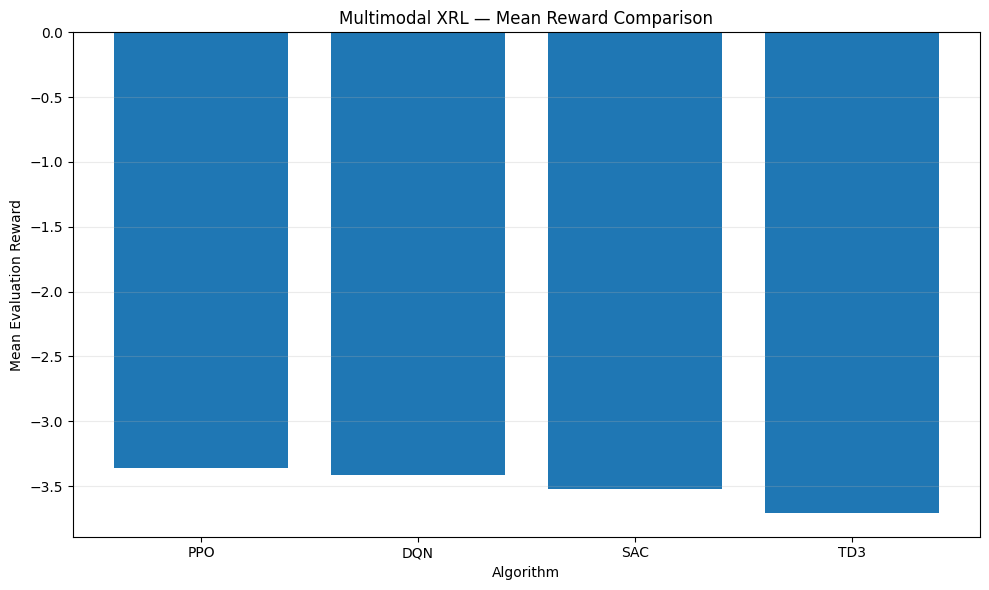

In [73]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Mean Reward"])
plt.xlabel("Algorithm")
plt.ylabel("Mean Evaluation Reward")
plt.title("Multimodal XRL — Mean Reward Comparison")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "mean_reward_comparison.pdf", dpi=600)
plt.show()

#### Reward Variance Comparison


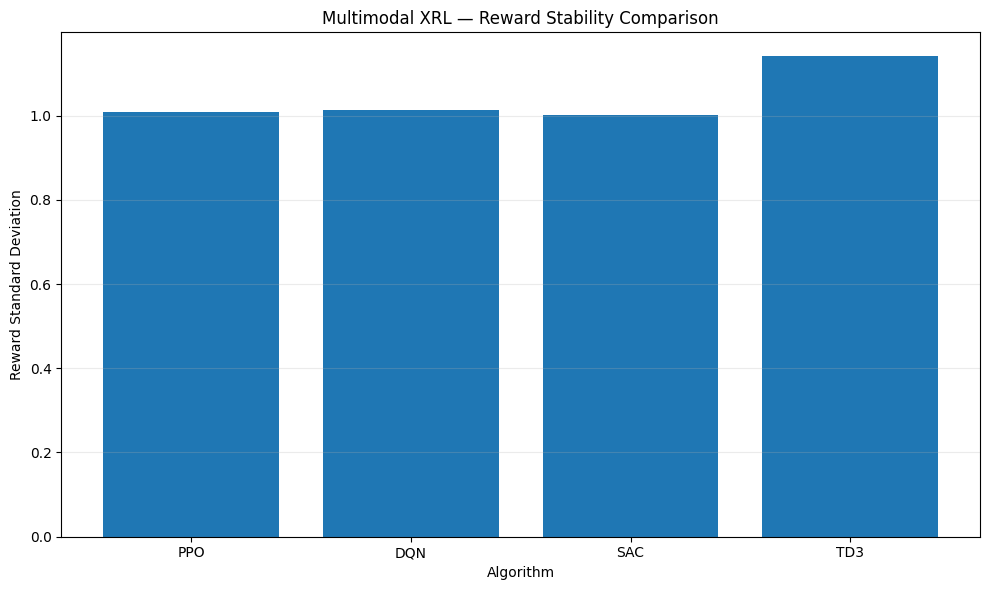

In [74]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Std Reward"])
plt.xlabel("Algorithm")
plt.ylabel("Reward Standard Deviation")
plt.title("Multimodal XRL — Reward Stability Comparison")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "reward_stability_comparison.pdf", dpi=600)
plt.show()

#### Success-Rate Comparison


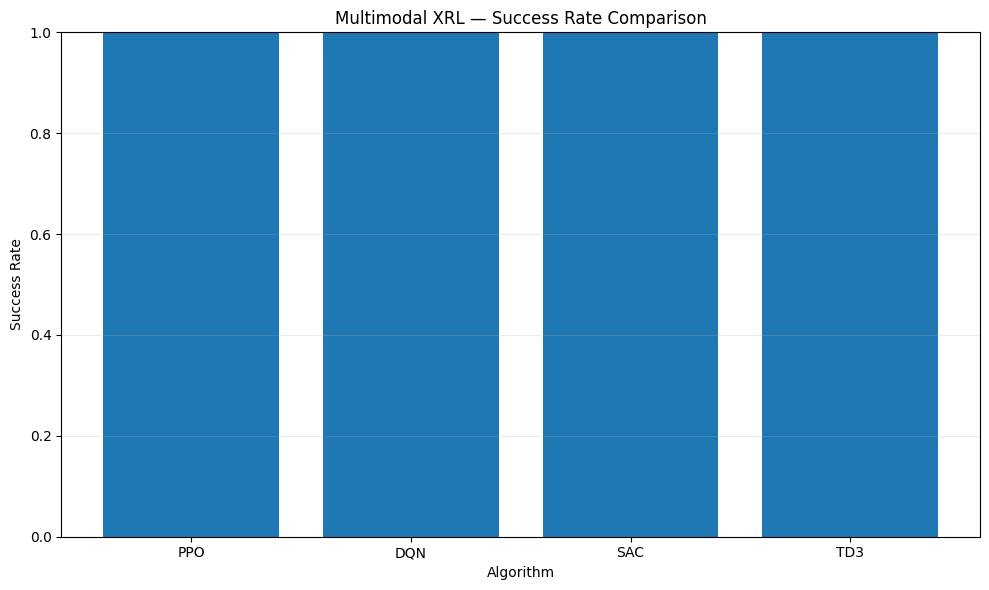

In [75]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Success Rate"])
plt.xlabel("Algorithm")
plt.ylabel("Success Rate")
plt.title("Multimodal XRL — Success Rate Comparison")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "success_rate_comparison.pdf", dpi=600)
plt.show()

#### Training-Time Comparison


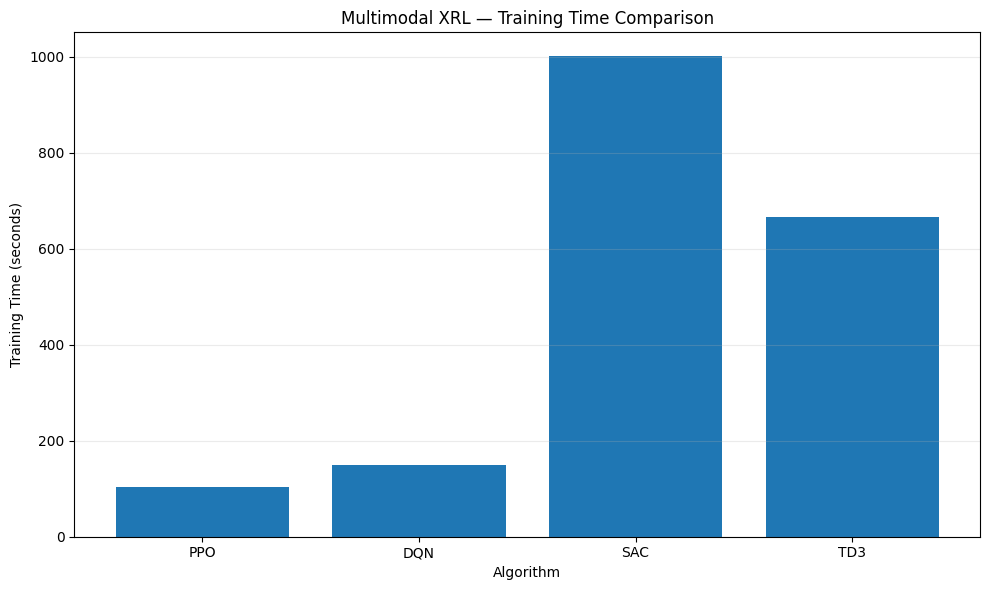

In [76]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Training Time"])
plt.xlabel("Algorithm")
plt.ylabel("Training Time (seconds)")
plt.title("Multimodal XRL — Training Time Comparison")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "training_time_comparison.png", dpi=200)
plt.show()

#### Inference-Time Comparison


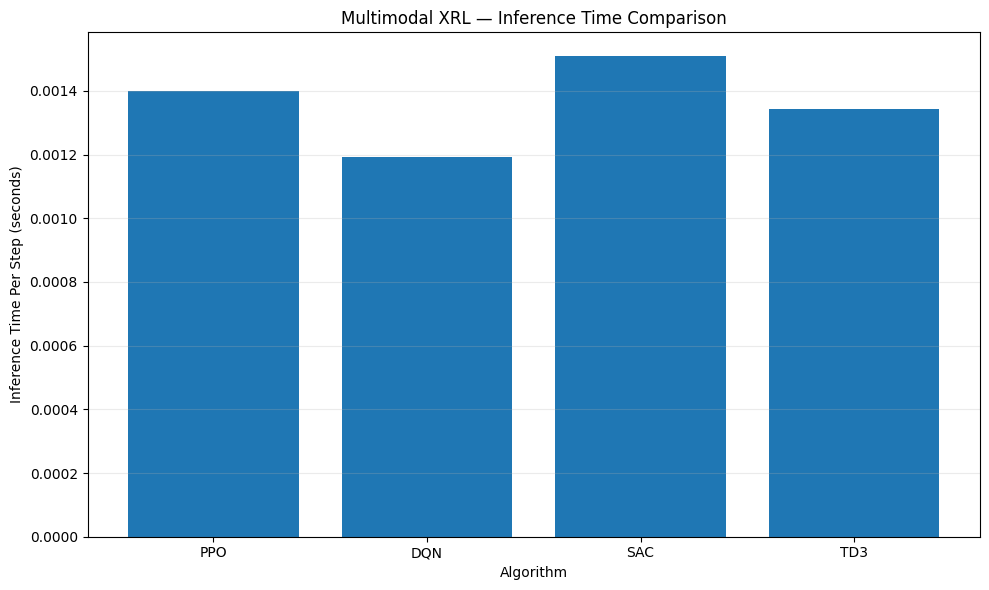

In [77]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Inference Time Per Step"])
plt.xlabel("Algorithm")
plt.ylabel("Inference Time Per Step (seconds)")
plt.title("Multimodal XRL — Inference Time Comparison")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "inference_time_comparison.png", dpi=200)
plt.show()

#### Model Parameter Comparison


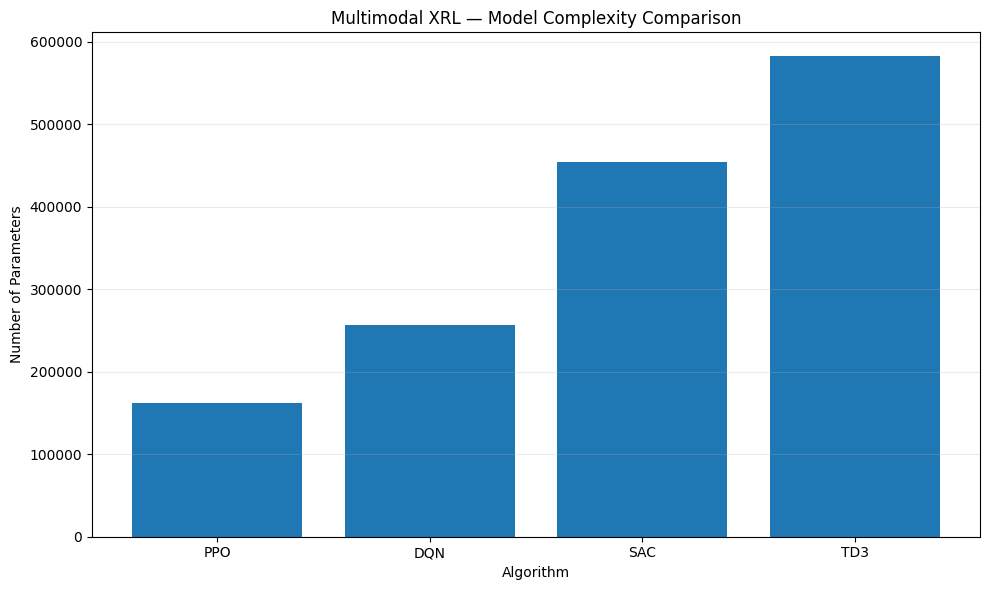

In [78]:
plt.figure(figsize=(10, 6))
plt.bar(comparison_df["Algorithm"], comparison_df["Parameter Count"])
plt.xlabel("Algorithm")
plt.ylabel("Number of Parameters")
plt.title("Multimodal XRL — Model Complexity Comparison")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "parameter_count_comparison.png", dpi=200)
plt.show()

#### Action Distribution


,Action Frequency - Road,Action Frequency - Rail,Action Frequency - Sea,Action Frequency - Air,Action Frequency - Inland Waterway
Algorithm,,,,,
PPO,0.0,1.000000,0.000000,0.0,0.000000
DQN,0.0,0.996667,0.003333,0.0,0.000000
SAC,0.0,0.990000,0.010000,0.0,0.000000
TD3,0.0,0.978889,0.003333,0.0,0.017778


<Axes: xlabel='Algorithm'>

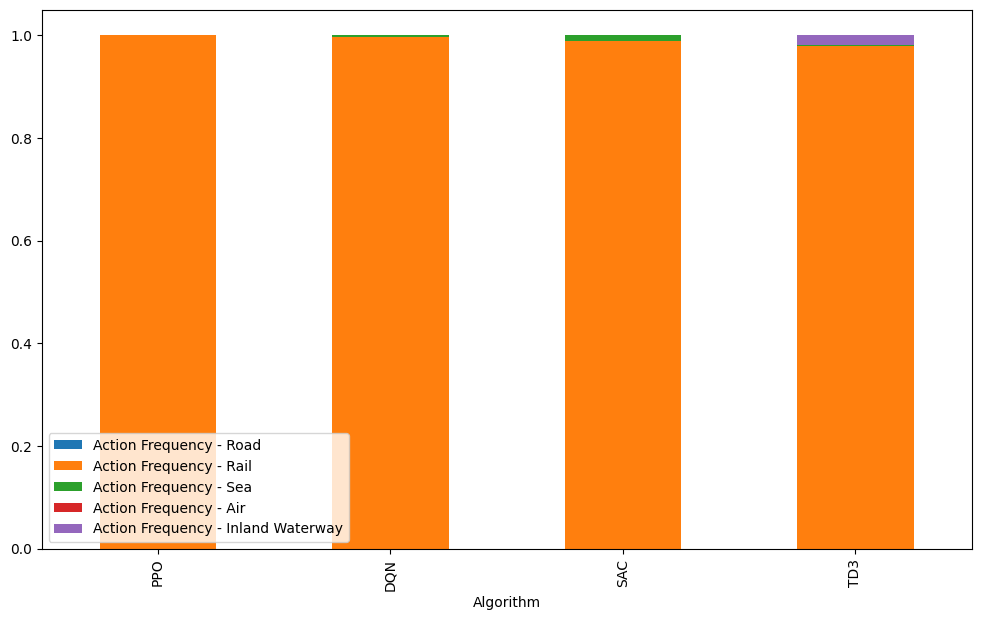

In [79]:
action_frequency_columns = [
    column
    for column in comparison_df.columns
    if column.startswith("Action Frequency -")
]


action_distribution = comparison_df[["Algorithm"] + action_frequency_columns].set_index(
    "Algorithm"
)


display(action_distribution)


action_distribution.plot(kind="bar", stacked=True, figsize=(12, 7))

### Calculate Modal Action Distributions


In [80]:
from collections import Counter


def calculate_action_distribution(model, env, algorithm, n_steps=1000):

    obs, _ = env.reset()

    action_counts = Counter()
    steps = 0

    while steps < n_steps:
        action, _ = model.predict(obs, deterministic=True)

        action_array = np.asarray(action)

        if action_array.size == 1:
            action_counts[str(action_array.item())] += 1

        else:
            for i, value in enumerate(action_array.flatten()):
                action_counts[f"Action_{i}"] += 1

        obs, reward, terminated, truncated, info = env.step(action)

        steps += 1

        if terminated or truncated:
            obs, _ = env.reset()

    total = sum(action_counts.values())

    frequencies = {action: count / total for action, count in action_counts.items()}

    return pd.Series(frequencies, name=algorithm)


action_distributions = {}

action_distributions["PPO"] = calculate_action_distribution(
    ppo_model, ppo_eval_env, "PPO"
)

action_distributions["TD3"] = calculate_action_distribution(
    td3_model, td3_eval_env, "TD3"
)

action_distributions["DQN"] = calculate_action_distribution(
    dqn_model, dqn_eval_env, "DQN"
)

print("Action distributions calculated successfully.")

display(pd.DataFrame(action_distributions).fillna(0))

Action distributions calculated successfully.


,PPO,TD3,DQN
1,1.0,0.0,0.993
2,0.0,0.0,0.007
Action_0,0.0,0.2,0.000
Action_1,0.0,0.2,0.000
Action_2,0.0,0.2,0.000
Action_3,0.0,0.2,0.000
Action_4,0.0,0.2,0.000


### Modal Action Distribution Plot


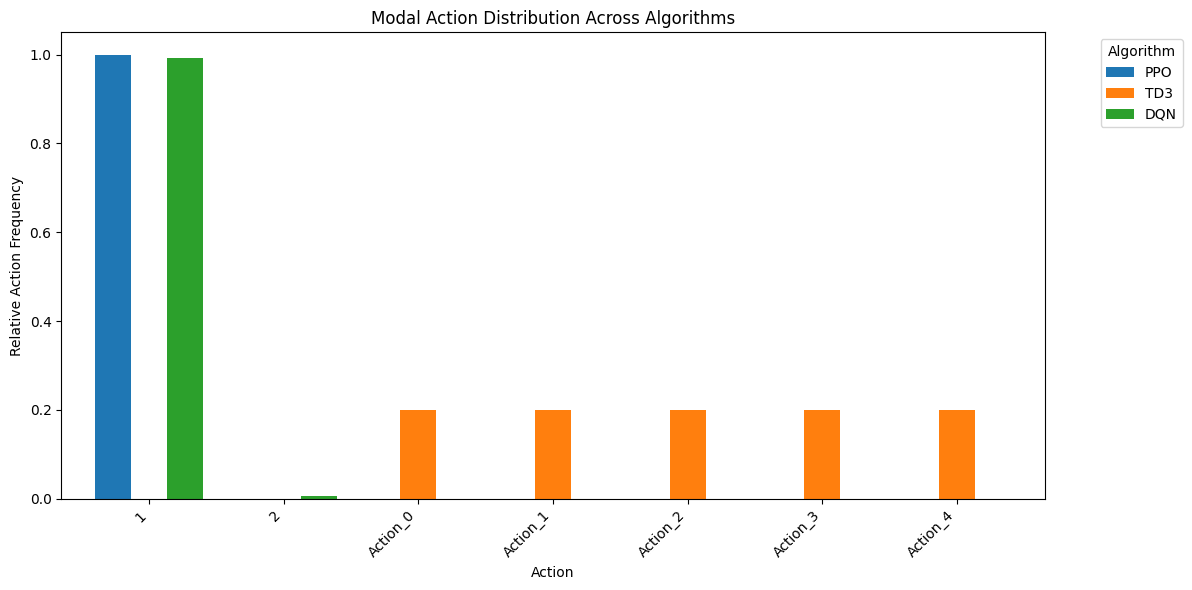

In [81]:
action_df = pd.DataFrame(action_distributions).fillna(0)

ax = action_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
)

ax.set_xlabel("Action")
ax.set_ylabel("Relative Action Frequency")
ax.set_title("Modal Action Distribution Across Algorithms")

ax.legend(
    title="Algorithm",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

comparison_dir = PLOTS_ROOT / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    comparison_dir / "action_distribution.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### Multi-Criteria Model Selection


In [82]:
selection_df = comparison_df.copy()

In [83]:
def minmax_score(series, higher_is_better=True):

    series = pd.to_numeric(series, errors="coerce")

    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(1.0, index=series.index)

    score = (series - minimum) / (maximum - minimum)

    if not higher_is_better:
        score = 1.0 - score

    return score

In [84]:
# Performance dimensions
selection_df["Score_Reward"] = minmax_score(
    selection_df["Mean Reward"], higher_is_better=True
)
selection_df["Score_Success"] = minmax_score(
    selection_df["Success Rate"], higher_is_better=True
)
selection_df["Score_Stability"] = minmax_score(
    selection_df["Std Reward"], higher_is_better=False
)
selection_df["Score_TrainingTime"] = minmax_score(
    selection_df["Training Time"], higher_is_better=False
)
selection_df["Score_InferenceTime"] = minmax_score(
    selection_df["Inference Time Per Step"], higher_is_better=False
)


# Research-oriented composite score
selection_df["Composite Score"] = (
    0.40 * selection_df["Score_Reward"]
    + 0.20 * selection_df["Score_Success"]
    + 0.20 * selection_df["Score_Stability"]
    + 0.10 * selection_df["Score_TrainingTime"]
    + 0.10 * selection_df["Score_InferenceTime"]
)
selection_df = selection_df.sort_values("Composite Score", ascending=False).reset_index(
    drop=True
)

display(
    selection_df[
        [
            "Algorithm",
            "Mean Reward",
            "Std Reward",
            "Success Rate",
            "Training Time",
            "Inference Time Per Step",
            "Composite Score",
        ]
    ]
)

,Algorithm,Mean Reward,Std Reward,Success Rate,Training Time,Inference Time Per Step,Composite Score
0,PPO,-3.361299,1.009601,1.0,104.312054,0.001399,0.922824
1,DQN,-3.415049,1.012066,1.0,150.208377,0.001192,0.916910
2,SAC,-3.522549,1.001323,1.0,1000.677477,0.001508,0.612364
3,TD3,-3.705049,1.140626,1.0,665.441098,0.001344,0.289409


### Automatic Best Model Selection


In [85]:
best_model_name = selection_df.iloc[0]["Algorithm"]
best_model_score = float(selection_df.iloc[0]["Composite Score"])

print(f"Best-performing model: {best_model_name}")
print(f"Composite score: {best_model_score:.4f}")

Best-performing model: PPO
Composite score: 0.9228


In [86]:
# Save model-selection result.
model_selection_result = {
    "best_model": best_model_name,
    "composite_score": best_model_score,
    "selection_weights": {
        "reward": 0.40,
        "success_rate": 0.20,
        "stability": 0.20,
        "training_time": 0.10,
        "inference_time": 0.10,
    },
}


with open(METRICS_ROOT / "best_model_selection.json", "w", encoding="utf-8") as f:
    json.dump(model_selection_result, f, indent=4)

### Final Test


#### Environments


In [87]:
final_test_env_discrete = make_monitored_env(
    test_df,
    test_modalities,
    "discrete",
    "FINAL_TEST_DQN_PPO",
    "test",
)


final_test_env_continuous = make_monitored_env(
    test_df,
    test_modalities,
    "continuous",
    "FINAL_TEST_SAC_TD3",
    "test",
)

#### Evaluation


In [88]:
models = {
    "PPO": ppo_model,
    "SAC": sac_model,
    "TD3": td3_model,
    "DQN": dqn_model,
}


final_test_results = []


for algorithm_name, model in models.items():
    if algorithm_name in ["PPO", "DQN"]:
        env = final_test_env_discrete

    else:
        env = final_test_env_continuous

    metrics, rewards, lengths = evaluate_model(
        model,
        env,
        CONFIG["evaluation_episodes"],
        f"{algorithm_name}_FINAL_TEST",
    )

    final_test_results.append(metrics)


final_test_df = pd.DataFrame(final_test_results)


final_test_df.to_csv(METRICS_ROOT / "final_test_results.csv", index=False)


display(final_test_df)

,Algorithm,Mean Reward,Std Reward,Best Reward,Final Reward,Mean Episode Length,Success Rate,Inference Time Per Step,Total Evaluation Time,Parameter Count,Action Frequency - Road,Action Frequency - Rail,Action Frequency - Sea,Action Frequency - Air,Action Frequency - Inland Waterway
0,PPO_FINAL_TEST,-3.431256,1.238749,-1.216227,-3.806281,30.0,1.0,0.001657,1.491736,161798,0.000000,1.000000,0.000000,0.000000,0.000000
1,SAC_FINAL_TEST,-3.727089,1.318762,-1.378758,-3.806281,30.0,1.0,0.001527,1.374590,454414,0.002222,0.984444,0.006667,0.004444,0.002222
2,TD3_FINAL_TEST,-3.932093,1.260720,-2.054473,-2.811033,30.0,1.0,0.001337,1.202866,582414,0.000000,0.967778,0.012222,0.000000,0.020000
3,DQN_FINAL_TEST,-3.453343,1.135973,-1.751890,-2.236033,30.0,1.0,0.001161,1.044507,257290,0.000000,0.995556,0.004444,0.000000,0.000000


#### Reward Distribution


In [89]:
final_reward_arrays = {
    "PPO": ppo_rewards,
    "SAC": sac_rewards,
    "TD3": td3_rewards,
    "DQN": dqn_rewards,
}

/tmp/ipykernel_45319/1248778218.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


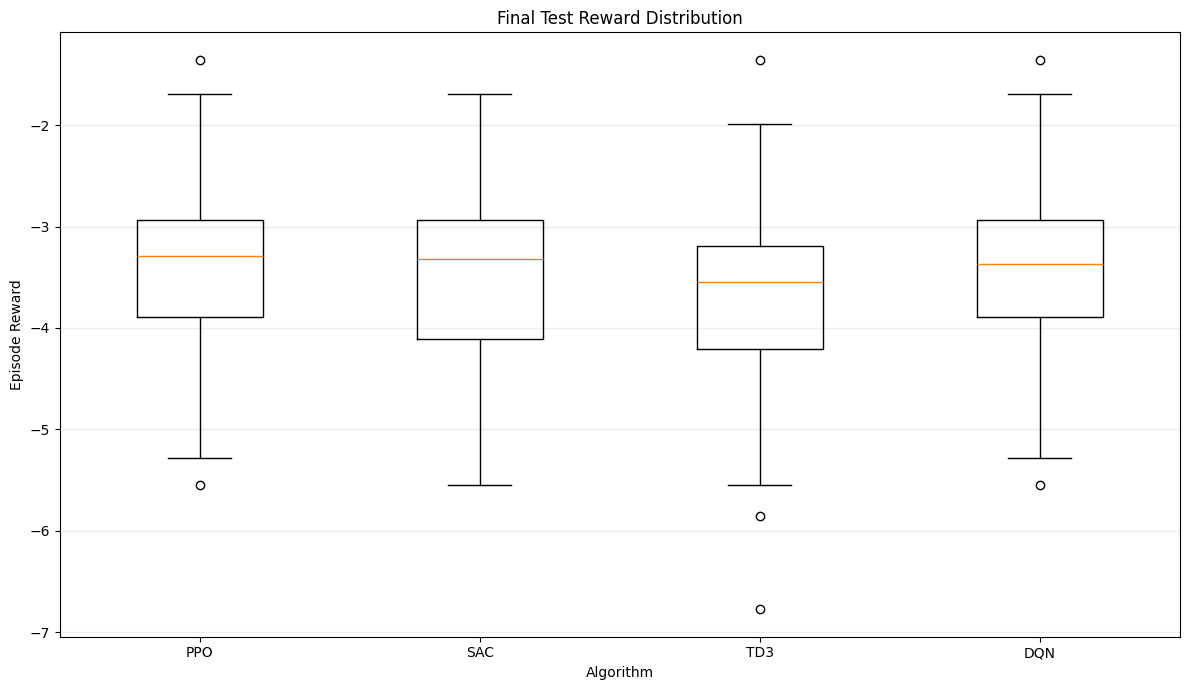

In [90]:
plt.figure(figsize=(12, 7))
plt.boxplot(
    [
        final_reward_arrays[name]
        for name in [
            "PPO",
            "SAC",
            "TD3",
            "DQN",
        ]
    ],
    labels=[
        "PPO",
        "SAC",
        "TD3",
        "DQN",
    ],
)
plt.xlabel("Algorithm")
plt.ylabel("Episode Reward")
plt.title("Final Test Reward Distribution")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_ROOT / "comparison" / "final_test_reward_distribution.png", dpi=200)
plt.show()

### Save Complete Experiment Metadata


In [91]:
experiment_metadata = {
    "seed": SEED,
    "data_root": str(DATA_ROOT),
    "dataset_manifest": DATASETS,
    "modality_columns": MODALITY_COLUMNS,
    "reward_parameters": REWARD_PARAMS,
    "mode_profiles": MODE_PROFILE,
    "algorithms": [
        "PPO",
        "SAC",
        "TD3",
        "DQN",
    ],
    "best_model": best_model_name,
    "best_model_composite_score": best_model_score,
    "configuration": CONFIG,
}

In [92]:
with open(RESULTS_ROOT / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(experiment_metadata, f, indent=4, default=str)

### Final Directory Summary


In [94]:
print("\nModels:")
for algorithm_name in models:
    print(f"  {algorithm_name}:", MODELS_ROOT / algorithm_name)

print("\nMetrics:")
print(" ", METRICS_ROOT)

print("\nPlots:")
print(" ", PLOTS_ROOT)

print("\nPreprocessing:")
print(" ", PREPROCESSING_ROOT)

print("\nBest model:")
print(" ", best_model_name)

print("\nComposite score:")
print(" ", best_model_score)


Models:
  PPO: results/models/PPO
  SAC: results/models/SAC
  TD3: results/models/TD3
  DQN: results/models/DQN

Metrics:
  results/metrics

Plots:
  results/plots

Preprocessing:
  results/preprocessing

Best model:
  PPO

Composite score:
  0.922824074335795
